# CS3807 – Deep Learning Laboratory
## Experiment 7: End-to-End Study of Autoencoders, Convolutional Autoencoders, Denoising Autoencoders and Variational Autoencoders

This notebook implements the complete experiment: fully connected autoencoder, convolutional autoencoder,
denoising convolutional autoencoder, and variational autoencoder (VAE) on the MNIST dataset.

**Dataset:** MNIST handwritten digits (28×28×1 grayscale images). Using 10,000 training and 2,000 test images.

**Models:** 
1. Fully Connected Autoencoder (latent dim 16)
2. Convolutional Autoencoder (spatial structure preservation)
3. Denoising Convolutional Autoencoder (Gaussian & salt-pepper noise)
4. Variational Autoencoder (latent dim 2 for visualization)


## 0. Imports and Configuration

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.datasets import mnist

from skimage.metrics import structural_similarity as ssim

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.figsize"] = (15, 4)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow version: 2.20.0
GPU available: True


In [2]:
# Configuration
TRAIN_SIZE = 10000
TEST_SIZE = 2000
IMAGE_SIZE = 28
CHANNELS = 1
EPOCHS_AE = 20
EPOCHS_VAE = 30
BATCH_SIZE = 128
LEARNING_RATE = 1e-3

print(f"Config: {TRAIN_SIZE} train, {TEST_SIZE} test, "
      f"image size {IMAGE_SIZE}x{IMAGE_SIZE}x{CHANNELS}")

Config: 10000 train, 2000 test, image size 28x28x1


## 3. Dataset and Experimental Setup

**MNIST Handwritten Digit Dataset:** 28×28×1 grayscale images of digits 0-9.

**Recommended subset:** 10,000 training images and 2,000 test images.

Expected input shape per image: (28, 28, 1)
Expected input per batch: (batch_size, 28, 28, 1)
Pixel values: normalized [0, 1]


In [3]:
# Load full data
(X_train_full, y_train_full), (X_test_full, y_test_full) = mnist.load_data()

# Normalize
X_train_full = X_train_full.astype('float32') / 255.0
X_test_full = X_test_full.astype('float32') / 255.0
X_train_full = X_train_full[..., np.newaxis]
X_test_full = X_test_full[..., np.newaxis]

# Stratified subset from training split
from sklearn.model_selection import train_test_split
X_train, _, y_train, _ = train_test_split(
    X_train_full, y_train_full, 
    train_size=TRAIN_SIZE,
    stratify=y_train_full,  # ← ensures balanced classes
    random_state=SEED
)

# Stratified subset from test split
X_test, _, y_test, _ = train_test_split(
    X_test_full, y_test_full,
    train_size=TEST_SIZE,
    stratify=y_test_full,
    random_state=SEED
)

# Verify balance
print("Training set class distribution:")
for i in range(10):
    print(f"  Digit {i}: {np.sum(y_train == i)}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training set class distribution:
  Digit 0: 987
  Digit 1: 1124
  Digit 2: 993
  Digit 3: 1022
  Digit 4: 974
  Digit 5: 904
  Digit 6: 986
  Digit 7: 1044
  Digit 8: 975
  Digit 9: 991


## 6. Exploring Autoencoders

An autoencoder learns to reproduce its input at the output.

The **encoder** maps the input to a lower-dimensional **latent representation**:
$$z = f_\theta(x)$$

The **decoder** reconstructs the input from the latent code:
$$\hat{x} = g_\phi(z)$$

The training objective minimizes **reconstruction error**:
$$L_{\mathrm{rec}} = \frac{1}{N} \sum_{i=1}^{N} \|x_i - \hat{x}_i\|^2$$

The latent vector $z$ is a **compressed representation** of the input, capturing the essential 
structure while discarding noise and irrelevant details.


## 7. Fully Connected Autoencoder

Architecture:
- Input: 784 (28×28 flattened)
- Dense 128 (ReLU)
- Dense 32 (ReLU)
- **Latent: 16 (linear)**
- Dense 32 (ReLU)
- Dense 128 (ReLU)
- Output: 784 (sigmoid)

Configuration:
- Optimizer: Adam (lr=1e-3)
- Loss: Binary cross-entropy
- Batch size: 128
- Epochs: 20


In [4]:
# Prepare flattened data for FC autoencoder
X_train_flat = X_train.reshape(-1, IMAGE_SIZE * IMAGE_SIZE * CHANNELS)
X_test_flat = X_test.reshape(-1, IMAGE_SIZE * IMAGE_SIZE * CHANNELS)

# Build FC Autoencoder
def build_fc_ae(latent_dim=16):
    inputs = keras.Input(shape=(IMAGE_SIZE * IMAGE_SIZE * CHANNELS,))
    # Encoder
    x = layers.Dense(128, activation='relu')(inputs)
    x = layers.Dense(32, activation='relu')(x)
    z = layers.Dense(latent_dim, activation='linear')(x)
    # Decoder
    x = layers.Dense(32, activation='relu')(z)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(IMAGE_SIZE * IMAGE_SIZE * CHANNELS, activation='sigmoid')(x)
    
    model = Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss='binary_crossentropy',
                  metrics=['mae'])
    return model

fc_ae = build_fc_ae(latent_dim=16)
fc_ae.summary()

I0000 00:00:1790786193.357078      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790786193.360260      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,040 (824.38 KB)

 Trainable params: 211,040 (824.38 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
print("Training FC Autoencoder...")
fc_ae_history = fc_ae.fit(
    X_train_flat, X_train_flat,
    validation_data=(X_test_flat, X_test_flat),
    epochs=EPOCHS_AE,
    batch_size=BATCH_SIZE,
    verbose=1
)

# Predictions
X_test_fc_recon = fc_ae.predict(X_test_flat, verbose=0).reshape(-1, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
print("FC Autoencoder training complete.")

Training FC Autoencoder...
Epoch 1/20
61/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4877 - mae: 0.3145

I0000 00:00:1790786198.623139     130 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 0.3385 - mae: 0.2033 - val_loss: 0.2476 - val_mae: 0.1408
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2280 - mae: 0.1273 - val_loss: 0.1986 - val_mae: 0.1079
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1908 - mae: 0.1023 - val_loss: 0.1780 - val_mae: 0.0950
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1737 - mae: 0.0907 - val_loss: 0.1654 - val_mae: 0.0855
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1632 - mae: 0.0833 - val_loss: 0.1575 - val_mae: 0.0800
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1563 - mae: 0.0786 - val_loss: 0.1521 - val_mae: 0.0762
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1510 - mae: 0.0750 - val_loss: 0.1472 - val_mae: 0.0727
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1457 - mae: 0.0713 - val_loss: 0.1423 - val_mae: 0.0689
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1414 - mae: 0.0681 - v

## 8. FC Autoencoder Analysis

**Plot 1: Original vs. Reconstructed Images**


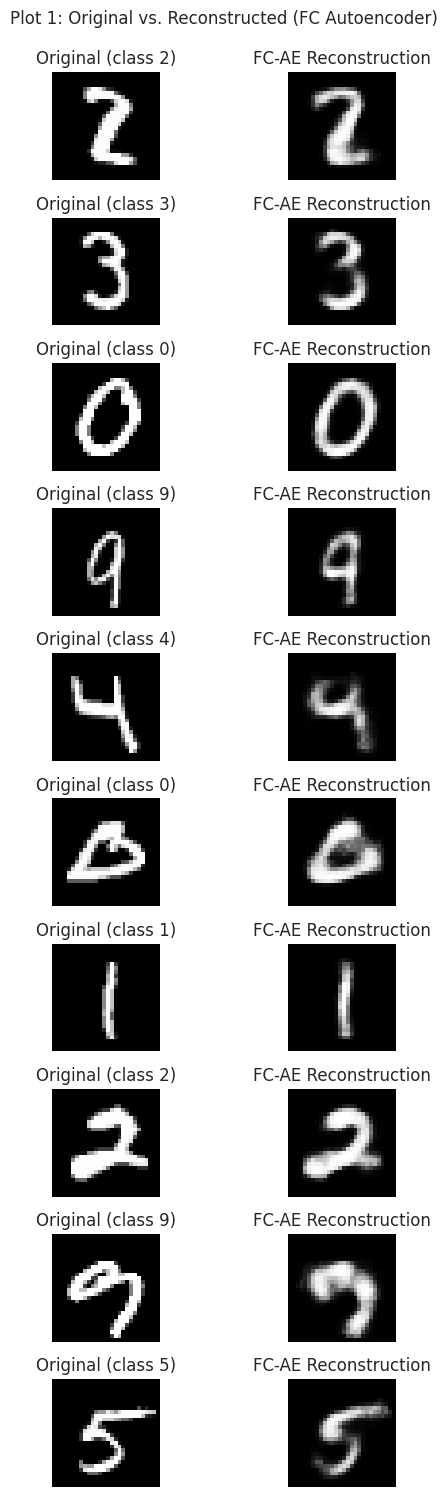

In [6]:
fig, axes = plt.subplots(10, 2, figsize=(6, 15))
for i in range(10):
    axes[i, 0].imshow(X_test[i].squeeze(), cmap='gray')
    axes[i, 0].set_title(f"Original (class {y_test[i]})")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(X_test_fc_recon[i].squeeze(), cmap='gray')
    axes[i, 1].set_title("FC-AE Reconstruction")
    axes[i, 1].axis('off')

fig.suptitle("Plot 1: Original vs. Reconstructed (FC Autoencoder)", fontsize=12, y=0.995)
plt.tight_layout()
plt.show()


**Plot 2: Training and Validation Loss**

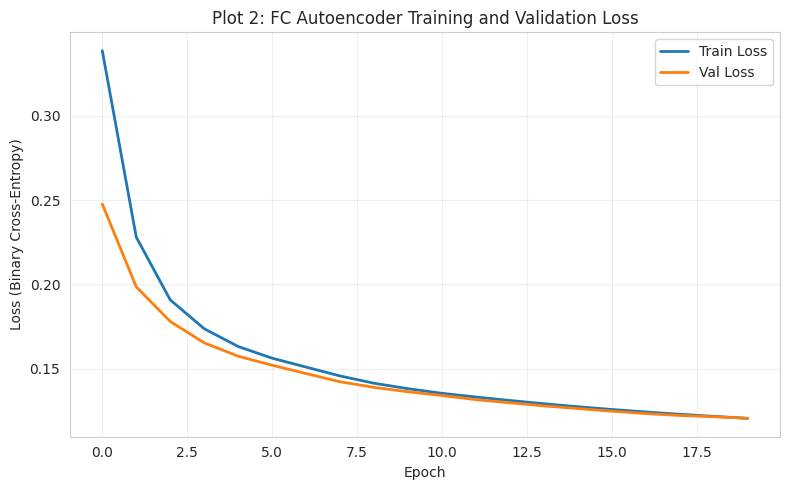

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(fc_ae_history.history['loss'], label='Train Loss', linewidth=2)
ax.plot(fc_ae_history.history['val_loss'], label='Val Loss', linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (Binary Cross-Entropy)')
ax.set_title('Plot 2: FC Autoencoder Training and Validation Loss')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Reconstruction Metrics

Evaluate on test set using MSE, MAE, and SSIM.


In [8]:
def compute_metrics(X_orig, X_recon):
    """Compute MSE, MAE, SSIM for reconstructed images."""
    X_orig_flat = X_orig.reshape(X_orig.shape[0], -1)
    X_recon_flat = X_recon.reshape(X_recon.shape[0], -1)
    
    mse = mean_squared_error(X_orig_flat, X_recon_flat)
    mae = mean_absolute_error(X_orig_flat, X_recon_flat)
    
    ssims = []
    for i in range(len(X_orig)):
        s = ssim(X_orig[i, :, :, 0], X_recon[i, :, :, 0], data_range=1.0)
        ssims.append(s)
    mean_ssim = np.mean(ssims)
    
    return {'MSE': mse, 'MAE': mae, 'SSIM': mean_ssim}

fc_ae_metrics = compute_metrics(X_test, X_test_fc_recon)
print("FC Autoencoder Metrics:")
print(f"  MSE:  {fc_ae_metrics['MSE']:.6f}")
print(f"  MAE:  {fc_ae_metrics['MAE']:.6f}")
print(f"  SSIM: {fc_ae_metrics['SSIM']:.4f}")

FC Autoencoder Metrics:
  MSE:  0.019565
  MAE:  0.052896
  SSIM: 0.7802


## 10. Convolutional Autoencoder

Preserves spatial structure using convolutional and transposed convolutional layers.

Architecture:
- Input: (28, 28, 1)
- Conv2D(32, 3×3, relu, same) + MaxPool(2)
- Conv2D(64, 3×3, relu, same) + MaxPool(2)
- Conv2D(64, 3×3, relu, same)
- UpSampling2D(2) + Conv2D(32, 3×3, relu, same)
- UpSampling2D(2) + Conv2D(1, 3×3, sigmoid, same)


In [9]:
def build_conv_ae(latent_spatial=(7, 7, 64)):
    inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
    # Encoder
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    # Decoder
    x = layers.UpSampling2D(2)(x)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    outputs = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    
    model = Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss='binary_crossentropy',
                  metrics=['mae'])
    return model

conv_ae = build_conv_ae()
conv_ae.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
print("Training Convolutional Autoencoder...")
conv_ae_history = conv_ae.fit(
    X_train, X_train,
    validation_data=(X_test, X_test),
    epochs=EPOCHS_AE,
    batch_size=BATCH_SIZE,
    verbose=1
)

X_test_conv_recon = conv_ae.predict(X_test, verbose=0)
print("Convolutional Autoencoder training complete.")

Training Convolutional Autoencoder...
Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - loss: 0.2232 - mae: 0.1288 - val_loss: 0.0985 - val_mae: 0.0400
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0906 - mae: 0.0330 - val_loss: 0.0827 - val_mae: 0.0274
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0821 - mae: 0.0264 - val_loss: 0.0794 - val_mae: 0.0249
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0786 - mae: 0.0237 - val_loss: 0.0759 - val_mae: 0.0221
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0763 - mae: 0.0219 - val_loss: 0.0741 - val_mae: 0.0207
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0748 - mae: 0.0207 - val_loss: 0.0728 - val_mae: 0.0196
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0737 - mae: 0.0197 - val_loss: 0.0717 - val_mae: 0.0188
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0729 - mae: 0.0191 - val_loss: 0.0714 - val_mae: 0.0184
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━

## 11. Comparing Fully Connected and Convolutional Autoencoders

**Plot 3: Reconstruction Comparison**


In [11]:
conv_ae_metrics = compute_metrics(X_test, X_test_conv_recon)

# Table
print("\nReconstruction Metrics Comparison:")
print(f"{'Model':<20} {'MSE':<12} {'MAE':<12} {'SSIM':<10} {'Parameters':<10}")
print(f"{'-'*60}")
print(f"{'FC Autoencoder':<20} {fc_ae_metrics['MSE']:<12.6f} {fc_ae_metrics['MAE']:<12.6f} "
      f"{fc_ae_metrics['SSIM']:<10.4f} {fc_ae.count_params():<10}")
print(f"{'Conv. Autoencoder':<20} {conv_ae_metrics['MSE']:<12.6f} {conv_ae_metrics['MAE']:<12.6f} "
      f"{conv_ae_metrics['SSIM']:<10.4f} {conv_ae.count_params():<10}")


Reconstruction Metrics Comparison:
Model                MSE          MAE          SSIM       Parameters
------------------------------------------------------------
FC Autoencoder       0.019565     0.052896     0.7802     211040    
Conv. Autoencoder    0.002394     0.014654     0.9761     74497     


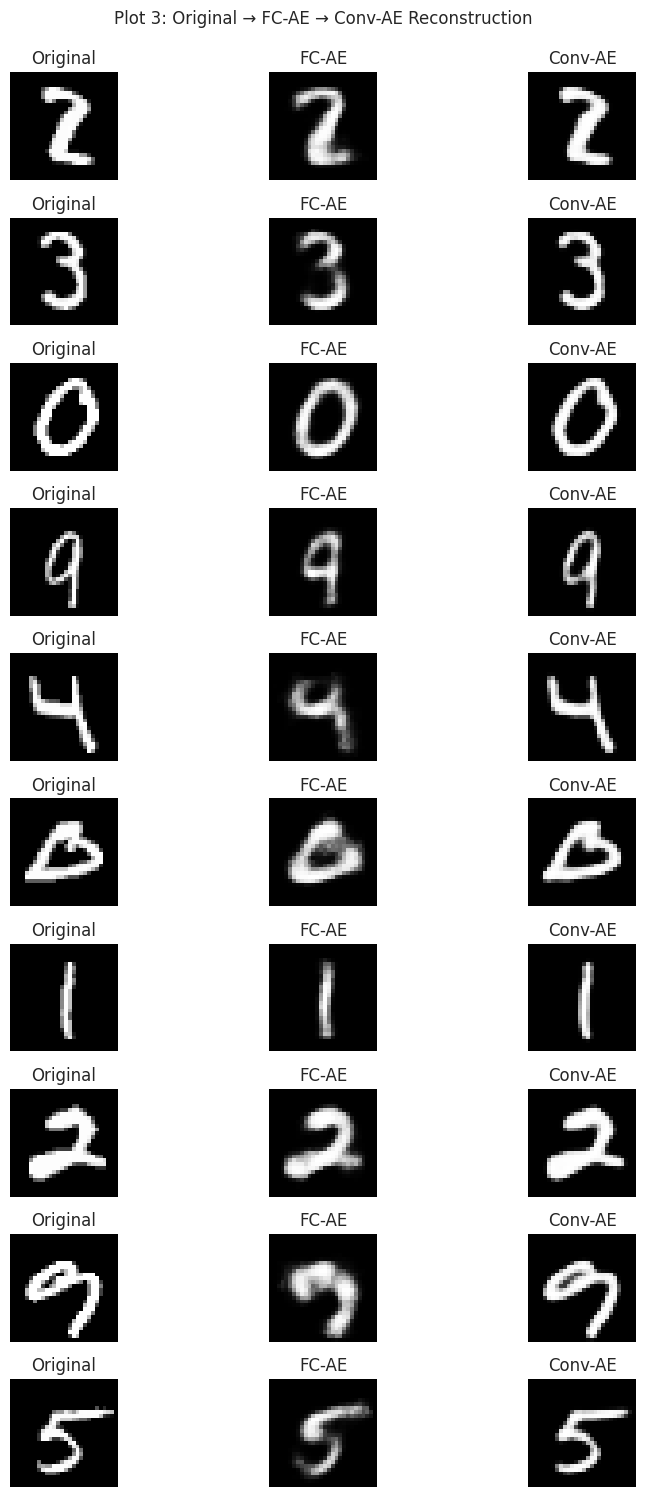

In [12]:
fig, axes = plt.subplots(10, 3, figsize=(9, 15))
for i in range(10):
    axes[i, 0].imshow(X_test[i].squeeze(), cmap='gray')
    axes[i, 0].set_title(f"Original")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(X_test_fc_recon[i].squeeze(), cmap='gray')
    axes[i, 1].set_title("FC-AE")
    axes[i, 1].axis('off')
    
    axes[i, 2].imshow(X_test_conv_recon[i].squeeze(), cmap='gray')
    axes[i, 2].set_title("Conv-AE")
    axes[i, 2].axis('off')

fig.suptitle("Plot 3: Original → FC-AE → Conv-AE Reconstruction", fontsize=12, y=0.995)
plt.tight_layout()
plt.show()


## 12-13. Denoising Convolutional Autoencoder

A denoising autoencoder receives corrupted input but reconstructs clean output.

We implement Gaussian noise and salt-and-pepper noise.


In [13]:
def add_gaussian_noise(X, sigma):
    """Add Gaussian noise N(0, sigma^2) to images, clip to [0, 1]."""
    noise = np.random.normal(0, sigma, X.shape)
    X_noisy = X + noise
    return np.clip(X_noisy, 0, 1)

def add_salt_pepper_noise(X, salt_pepper_ratio):
    """Add salt-and-pepper noise at given ratio."""
    X_noisy = X.copy()
    num_pixels = X.size
    num_corrupt = int(num_pixels * salt_pepper_ratio)
    random_indices = np.random.choice(num_pixels, num_corrupt, replace=False)
    
    X_noisy_flat = X_noisy.flatten()
    X_noisy_flat[random_indices] = np.random.choice([0, 1], num_corrupt)
    return X_noisy_flat.reshape(X.shape)

# Generate noisy versions (Gaussian noise)
noise_levels = [0.1, 0.2, 0.3]
X_train_noisy_dict = {}
X_test_noisy_dict = {}

for sigma in noise_levels:
    X_train_noisy_dict[sigma] = add_gaussian_noise(X_train, sigma)
    X_test_noisy_dict[sigma] = add_gaussian_noise(X_test, sigma)

print(f"Created noisy versions with Gaussian noise σ ∈ {noise_levels}")

Created noisy versions with Gaussian noise σ ∈ [0.1, 0.2, 0.3]


In [14]:
# Train denoising autoencoder (using sigma=0.2 as main model)
sigma_main = 0.2

def build_denoising_ae():
    inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
    # Encoder
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    # Decoder
    x = layers.UpSampling2D(2)(x)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    outputs = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    
    model = Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss='binary_crossentropy',
                  metrics=['mae'])
    return model

denoising_ae = build_denoising_ae()

print(f"Training Denoising Autoencoder (σ={sigma_main})...")
denoising_ae_history = denoising_ae.fit(
    X_train_noisy_dict[sigma_main], X_train,  # noisy input -> clean output
    validation_data=(X_test_noisy_dict[sigma_main], X_test),
    epochs=EPOCHS_AE,
    batch_size=BATCH_SIZE,
    verbose=1
)

X_test_denoised = denoising_ae.predict(X_test_noisy_dict[sigma_main], verbose=0)
print("Denoising Autoencoder training complete.")

Training Denoising Autoencoder (σ=0.2)...
Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - loss: 0.2733 - mae: 0.1614 - val_loss: 0.1240 - val_mae: 0.0585
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1087 - mae: 0.0464 - val_loss: 0.0961 - val_mae: 0.0379
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0925 - mae: 0.0344 - val_loss: 0.0873 - val_mae: 0.0312
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0870 - mae: 0.0303 - val_loss: 0.0835 - val_mae: 0.0282
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0840 - mae: 0.0280 - val_loss: 0.0815 - val_mae: 0.0265
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0821 - mae: 0.0265 - val_loss: 0.0799 - val_mae: 0.0253
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0808 - mae: 0.0255 - val_loss: 0.0789 - val_mae: 0.0245
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0798 - mae: 0.0248 - val_loss: 0.0781 - val_mae: 0.0239
Epoch 9/20
79/79 ━━━━━━━━━━━━

## 14. Denoising Autoencoder Analysis

**Plot 4: Clean vs. Noisy vs. Denoised**


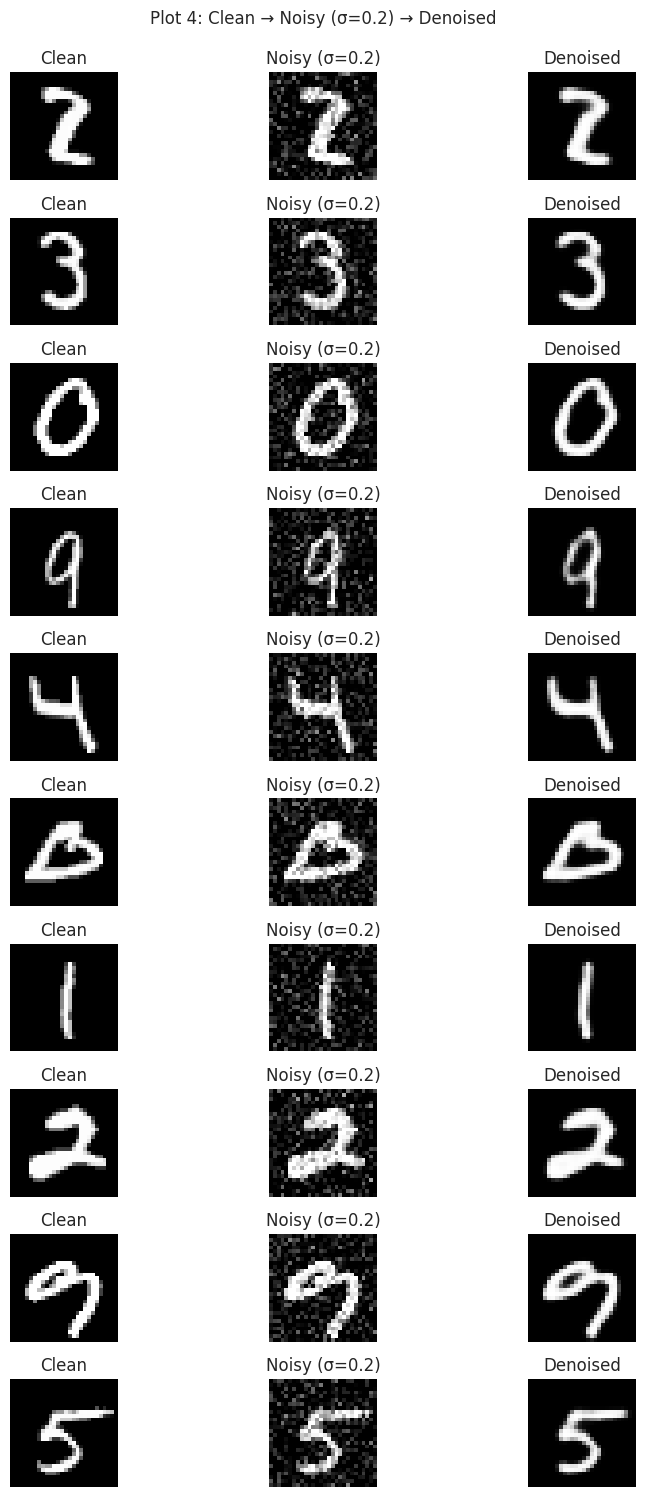

In [15]:
fig, axes = plt.subplots(10, 3, figsize=(9, 15))
for i in range(10):
    axes[i, 0].imshow(X_test[i].squeeze(), cmap='gray')
    axes[i, 0].set_title("Clean")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(X_test_noisy_dict[sigma_main][i].squeeze(), cmap='gray')
    axes[i, 1].set_title(f"Noisy (σ={sigma_main})")
    axes[i, 1].axis('off')
    
    axes[i, 2].imshow(X_test_denoised[i].squeeze(), cmap='gray')
    axes[i, 2].set_title("Denoised")
    axes[i, 2].axis('off')

fig.suptitle(f"Plot 4: Clean → Noisy (σ={sigma_main}) → Denoised", fontsize=12, y=0.995)
plt.tight_layout()
plt.show()


**Plot 5: Noise Level vs. Reconstruction Quality**

In [16]:
noise_quality_results = []

for sigma in [0.1, 0.2, 0.3]:
    X_noisy_test = X_test_noisy_dict[sigma]
    X_denoised_test = denoising_ae.predict(X_noisy_test, verbose=0)
    
    # Compute metrics: denoised vs. clean
    metrics_dict = compute_metrics(X_test, X_denoised_test)
    noise_quality_results.append({
        'Noise Level': sigma,
        'MSE': metrics_dict['MSE'],
        'MAE': metrics_dict['MAE'],
        'SSIM': metrics_dict['SSIM']
    })

print("Noise Level vs. Reconstruction Quality:")
print(f"{'Noise σ':<10} {'MSE':<12} {'MAE':<12} {'SSIM':<10}")
print(f"{'-'*44}")
for r in noise_quality_results:
    print(f"{r['Noise Level']:<10.1f} {r['MSE']:<12.6f} {r['MAE']:<12.6f} {r['SSIM']:<10.4f}")

Noise Level vs. Reconstruction Quality:
Noise σ    MSE          MAE          SSIM      
--------------------------------------------
0.1        0.003353     0.017128     0.9625    
0.2        0.004373     0.020662     0.9488    
0.3        0.006733     0.028373     0.8903    


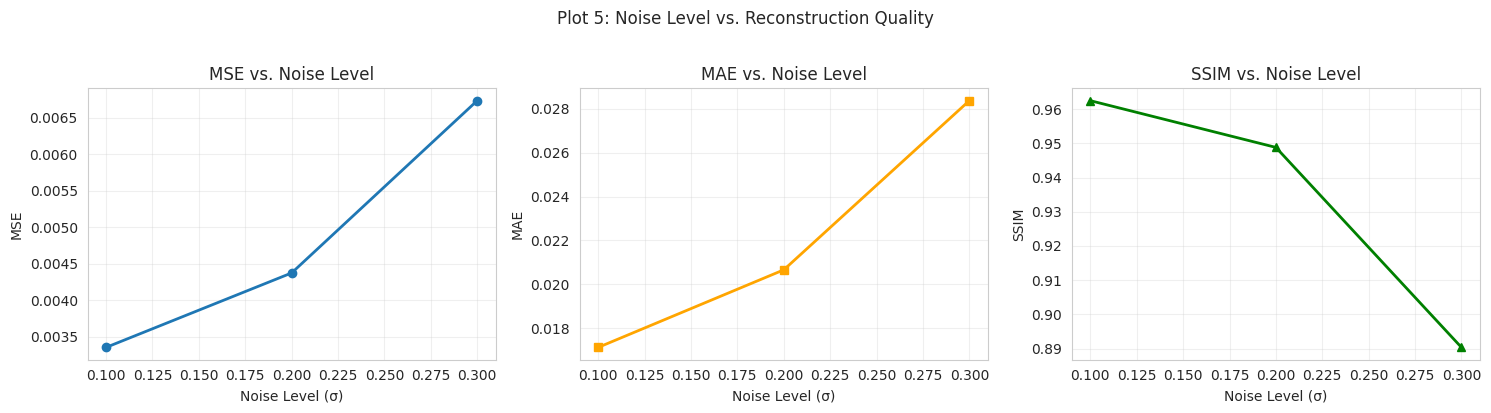

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
noise_levels_plot = [r['Noise Level'] for r in noise_quality_results]
mse_vals = [r['MSE'] for r in noise_quality_results]
mae_vals = [r['MAE'] for r in noise_quality_results]
ssim_vals = [r['SSIM'] for r in noise_quality_results]

axes[0].plot(noise_levels_plot, mse_vals, marker='o', linewidth=2)
axes[0].set_xlabel('Noise Level (σ)')
axes[0].set_ylabel('MSE')
axes[0].set_title('MSE vs. Noise Level')
axes[0].grid(alpha=0.3)

axes[1].plot(noise_levels_plot, mae_vals, marker='s', linewidth=2, color='orange')
axes[1].set_xlabel('Noise Level (σ)')
axes[1].set_ylabel('MAE')
axes[1].set_title('MAE vs. Noise Level')
axes[1].grid(alpha=0.3)

axes[2].plot(noise_levels_plot, ssim_vals, marker='^', linewidth=2, color='green')
axes[2].set_xlabel('Noise Level (σ)')
axes[2].set_ylabel('SSIM')
axes[2].set_title('SSIM vs. Noise Level')
axes[2].grid(alpha=0.3)

fig.suptitle("Plot 5: Noise Level vs. Reconstruction Quality", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()


## 15-17. Variational Autoencoder

A VAE learns a **probabilistic latent representation** instead of a deterministic code.

The encoder produces mean and log-variance:
$$\mu(x), \log \sigma^2(x)$$

Sampling uses the **reparameterization trick**:
$$z = \mu + \sigma \odot \epsilon, \quad \epsilon \sim N(0, I)$$

The VAE loss combines:
1. **Reconstruction loss** (binary cross-entropy)
2. **KL divergence** to regularize the latent distribution


In [18]:
# VAE with 2D latent space for visualization
LATENT_DIM_VAE = 2

class VAE(keras.Model):
    def __init__(self, latent_dim=2, **kwargs):
        super(VAE, self).__init__(**kwargs)
        self.latent_dim = latent_dim
        
        # Encoder
        self.encoder_input = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
        x = layers.Conv2D(32, 3, activation='relu', padding='same')(self.encoder_input)
        x = layers.MaxPooling2D(2, padding='same')(x)
        x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
        x = layers.MaxPooling2D(2, padding='same')(x)
        x = layers.Flatten()(x)
        x = layers.Dense(16, activation='relu')(x)
        
        self.z_mean = layers.Dense(latent_dim, name='z_mean')(x)
        self.z_log_var = layers.Dense(latent_dim, name='z_log_var')(x)
        
        self.encoder = Model(self.encoder_input, [self.z_mean, self.z_log_var])
        
        # Decoder
        latent_inputs = keras.Input(shape=(latent_dim,))
        x = layers.Dense(16, activation='relu')(latent_inputs)
        x = layers.Dense(7 * 7 * 64, activation='relu')(x)
        x = layers.Reshape((7, 7, 64))(x)
        x = layers.UpSampling2D(2)(x)
        x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
        x = layers.UpSampling2D(2)(x)
        decoder_outputs = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
        self.decoder = Model(latent_inputs, decoder_outputs)
    
    def call(self, inputs):
        z_mean, z_log_var = self.encoder(inputs)
        # Reparameterization trick
        eps = tf.random.normal(shape=(tf.shape(z_mean)[0], self.latent_dim))
        z = z_mean + tf.exp(0.5 * z_log_var) * eps
        reconstructed = self.decoder(z)
        return reconstructed, z_mean, z_log_var, z
    
    def train_step(self, data):
        if isinstance(data, tuple):
            x = data[0]
        else:
            x = data
        
        with tf.GradientTape() as tape:
            reconstructed, z_mean, z_log_var, z = self(x, training=True)
            
            # Reconstruction loss
            reconstruction_loss = tf.reduce_mean(
                tf.keras.losses.binary_crossentropy(x, reconstructed)
            ) * (IMAGE_SIZE * IMAGE_SIZE)
            
            # KL divergence
            kl_loss = -0.5 * tf.reduce_mean(
                1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)
            )
            
            total_loss = reconstruction_loss + kl_loss
        
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        
        return {
            'loss': total_loss,
            'reconstruction_loss': reconstruction_loss,
            'kl_loss': kl_loss
        }

vae = VAE(latent_dim=LATENT_DIM_VAE)
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE))

print("Training VAE...")
vae_history = vae.fit(X_train, epochs=EPOCHS_VAE, batch_size=BATCH_SIZE, verbose=1)
print("VAE training complete.")

Training VAE...
Epoch 1/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - kl_loss: 2.0879 - loss: 205.6949 - reconstruction_loss: 203.6070
Epoch 2/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - kl_loss: 2.8028 - loss: 197.2312 - reconstruction_loss: 194.4284
Epoch 3/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - kl_loss: 2.8191 - loss: 190.2455 - reconstruction_loss: 187.4265
Epoch 4/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - kl_loss: 2.9190 - loss: 191.6306 - reconstruction_loss: 188.7117
Epoch 5/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - kl_loss: 2.6305 - loss: 181.9975 - reconstruction_loss: 179.3670
Epoch 6/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - kl_loss: 2.0142 - loss: 179.6832 - reconstruction_loss: 177.6689
Epoch 7/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - kl_loss: 2.0202 - loss: 178.1768 - reconstruction_loss: 176.1567
Epoch 8/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - kl_loss: 3.2425 - loss: 169.8547 - reconstruction_loss: 166.6122
Epoch 9/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/st

In [19]:
# Get reconstructions and latent codes
X_test_vae_recon, z_test_mean, z_test_log_var, z_test = vae(X_test)
X_test_vae_recon = X_test_vae_recon.numpy()

vae_metrics = compute_metrics(X_test, X_test_vae_recon)
print("VAE Reconstruction Metrics:")
print(f"  MSE:  {vae_metrics['MSE']:.6f}")
print(f"  MAE:  {vae_metrics['MAE']:.6f}")
print(f"  SSIM: {vae_metrics['SSIM']:.4f}")

VAE Reconstruction Metrics:
  MSE:  0.047017
  MAE:  0.109488
  SSIM: 0.4668


## 18. Exploring the VAE Latent Space

Since the latent dimension is 2, we can visualize how test images are encoded.

**Plot 6: VAE Latent Space**


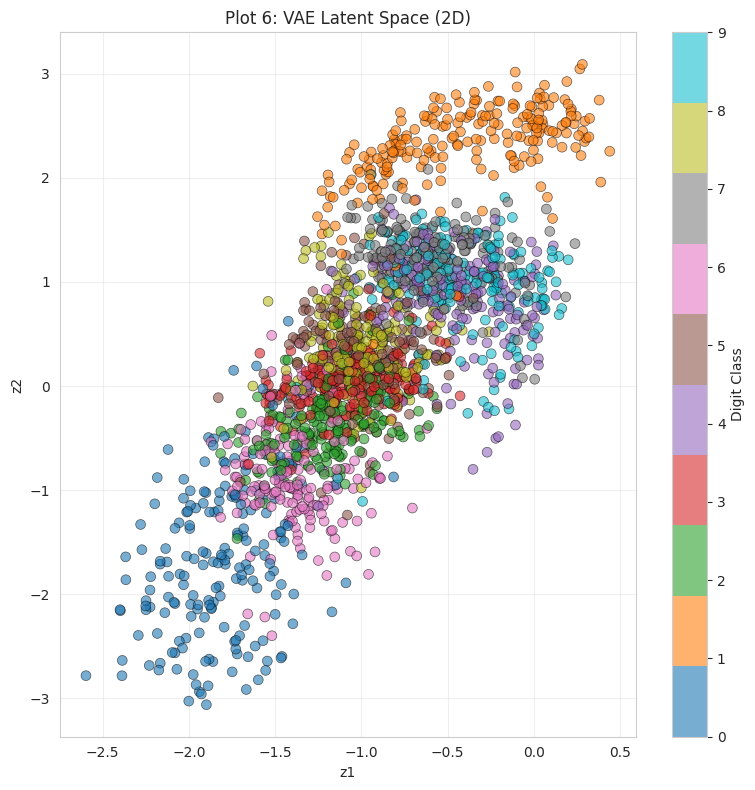

In [20]:
fig, ax = plt.subplots(figsize=(8, 8))

scatter = ax.scatter(z_test_mean[:, 0], z_test_mean[:, 1], c=y_test, 
                     cmap='tab10', s=50, alpha=0.6, edgecolors='k', linewidth=0.5)
ax.set_xlabel('z1')
ax.set_ylabel('z2')
ax.set_title('Plot 6: VAE Latent Space (2D)')
cbar = plt.colorbar(scatter, ax=ax, label='Digit Class')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 19. Generating New Images with the VAE

Sample random points from the latent distribution and pass through decoder.

**Plot 7: Randomly Generated Images**


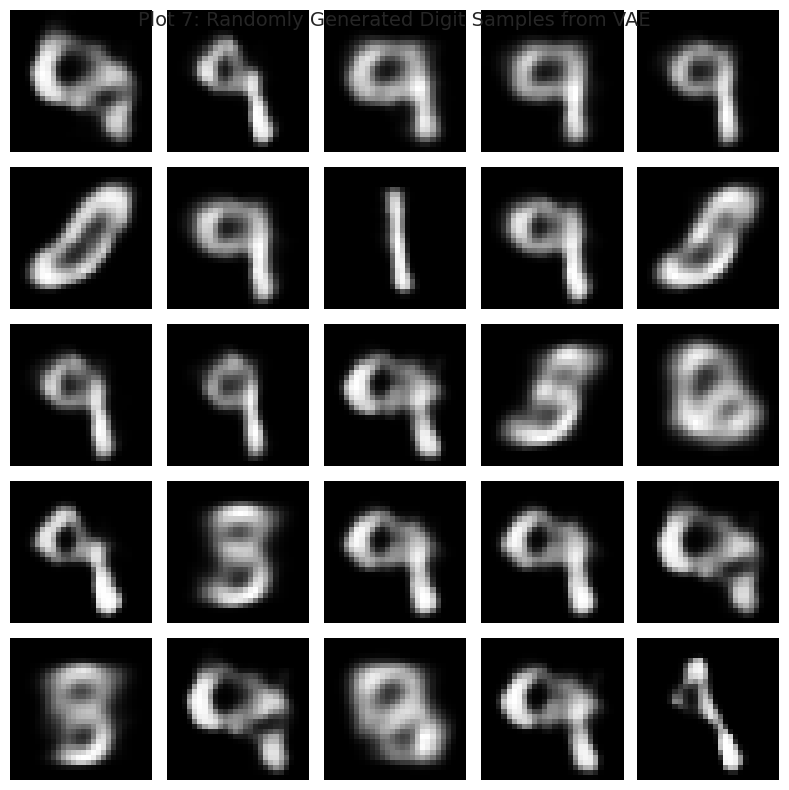

In [21]:
# Generate random samples
num_samples = 25
z_samples = np.random.normal(0, 1, (num_samples, LATENT_DIM_VAE)).astype('float32')
generated_images = vae.decoder(z_samples).numpy()

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for idx, ax in enumerate(axes.flat):
    ax.imshow(generated_images[idx].squeeze(), cmap='gray')
    # ax.set_title(f"z={z_samples[idx]}") # Removed this line
    ax.axis('off')

plt.tight_layout()
fig.suptitle("Plot 7: Randomly Generated Digit Samples from VAE", fontsize=14, y=0.98)
plt.show()



## 20. Latent Space Interpolation

Interpolate between two latent codes to show smooth transitions.

**Plot 8: Latent Space Interpolation**


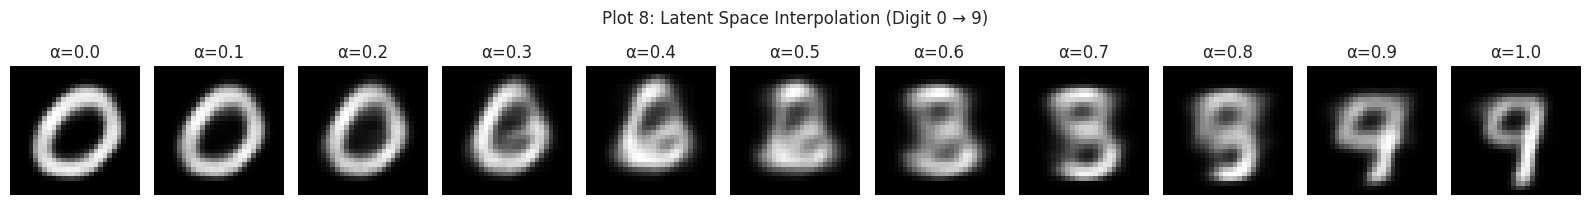

In [22]:
# Select two random test samples from different digit classes
idx_a = np.where(y_test == 0)[0][0]  # digit 0
idx_b = np.where(y_test == 9)[0][0]  # digit 9

z_a = z_test_mean[idx_a].numpy()
z_b = z_test_mean[idx_b].numpy()

# Interpolate
alphas = np.linspace(0, 1, 11)
interpolated_latents = np.array([
    (1 - alpha) * z_a + alpha * z_b for alpha in alphas
]).astype('float32')

interpolated_images = vae.decoder(interpolated_latents).numpy()

fig, axes = plt.subplots(1, 11, figsize=(16, 2))
for idx, (ax, img, alpha) in enumerate(zip(axes, interpolated_images, alphas)):
    ax.imshow(img.squeeze(), cmap='gray')
    ax.set_title(f"α={alpha:.1f}")
    ax.axis('off')

fig.suptitle("Plot 8: Latent Space Interpolation (Digit 0 → 9)", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()


## 21. Reconstruction Comparison Across All Models

Consolidated metrics across all four autoencoder variants.


In [23]:
consolidated_results = {
    'Model': ['FC Autoencoder', 'Conv. Autoencoder', 'Denoising CAE', 'VAE'],
    'MSE': [fc_ae_metrics['MSE'], conv_ae_metrics['MSE'], 
            compute_metrics(X_test, X_test_denoised)['MSE'], vae_metrics['MSE']],
    'MAE': [fc_ae_metrics['MAE'], conv_ae_metrics['MAE'],
            compute_metrics(X_test, X_test_denoised)['MAE'], vae_metrics['MAE']],
    'SSIM': [fc_ae_metrics['SSIM'], conv_ae_metrics['SSIM'],
             compute_metrics(X_test, X_test_denoised)['SSIM'], vae_metrics['SSIM']],
    'Parameters': [fc_ae.count_params(), conv_ae.count_params(), 
                   denoising_ae.count_params(), sum([w.shape.num_elements() for w in vae.trainable_weights]) // 2]
}

import pandas as pd
results_df = pd.DataFrame(consolidated_results)
print("\nConsolidated Reconstruction Results:")
print(results_df.to_string(index=False))


Consolidated Reconstruction Results:
            Model      MSE      MAE     SSIM  Parameters
   FC Autoencoder 0.019565 0.052896 0.780199      211040
Conv. Autoencoder 0.002394 0.014654 0.976111       74497
    Denoising CAE 0.004373 0.020662 0.948802       74497
              VAE 0.047017 0.109488 0.466789       70594


## 23. Reconstruction Error Distribution

**Plot 9: Distribution of Reconstruction Errors**


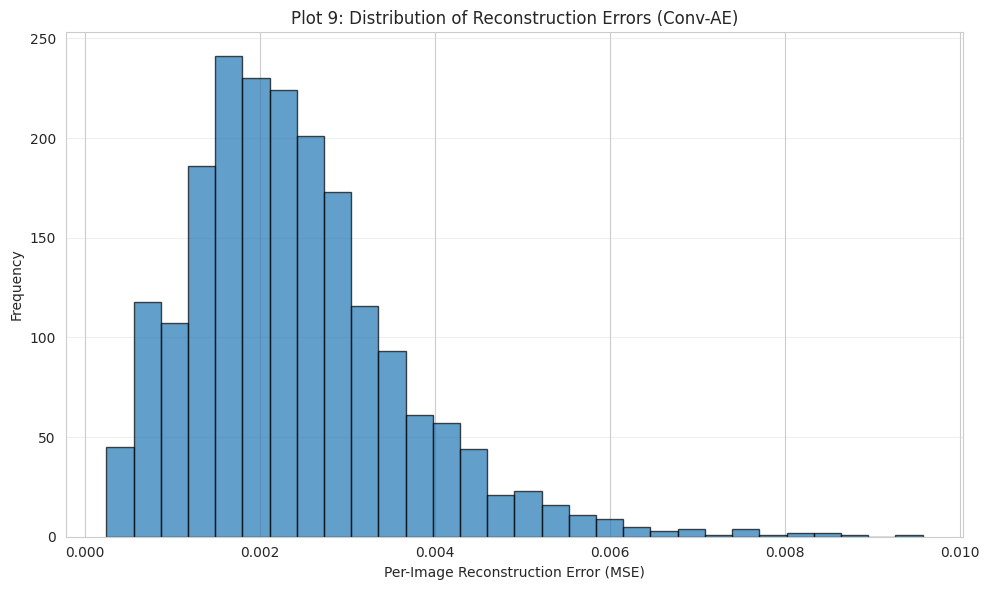

In [24]:
# Calculate per-image reconstruction error for Conv-AE (best performer)
def per_image_mse(X_orig, X_recon):
    return np.mean((X_orig - X_recon)**2, axis=(1, 2, 3))

errors_conv = per_image_mse(X_test, X_test_conv_recon)

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(errors_conv, bins=30, edgecolor='black', alpha=0.7)
ax.set_xlabel('Per-Image Reconstruction Error (MSE)')
ax.set_ylabel('Frequency')
ax.set_title('Plot 9: Distribution of Reconstruction Errors (Conv-AE)')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()


## 24. High-Error Image Analysis

Identify and display the five test images with largest reconstruction errors.


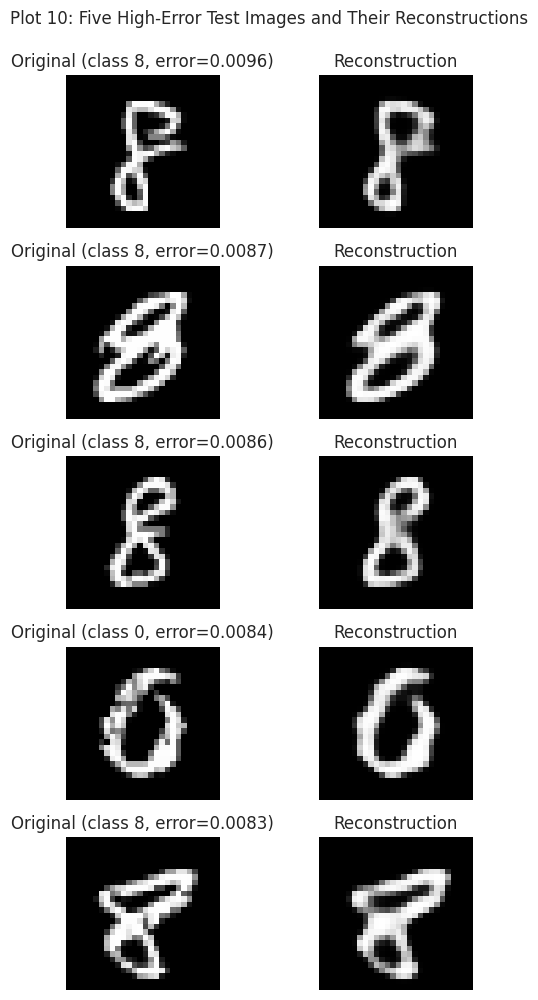

In [25]:
# Find top 5 high-error images
top_5_indices = np.argsort(errors_conv)[-5:][::-1]

fig, axes = plt.subplots(5, 2, figsize=(6, 10))
for row, idx in enumerate(top_5_indices):
    axes[row, 0].imshow(X_test[idx].squeeze(), cmap='gray')
    axes[row, 0].set_title(f"Original (class {y_test[idx]}, error={errors_conv[idx]:.4f})")
    axes[row, 0].axis('off')
    
    axes[row, 1].imshow(X_test_conv_recon[idx].squeeze(), cmap='gray')
    axes[row, 1].set_title("Reconstruction")
    axes[row, 1].axis('off')

fig.suptitle("Plot 10: Five High-Error Test Images and Their Reconstructions", fontsize=12, y=0.995)
plt.tight_layout()
plt.show()


## 27. Additional Exercise: Latent Dimension Study

Repeat the basic FC autoencoder with different latent dimensions.


In [26]:
latent_dims = [2, 8, 16, 32]
latent_study_results = []

for latent_d in latent_dims:
    print(f"Training FC-AE with latent_dim={latent_d}...")
    ae_latent = build_fc_ae(latent_dim=latent_d)
    ae_latent.fit(X_train_flat, X_train_flat,
                  validation_data=(X_test_flat, X_test_flat),
                  epochs=EPOCHS_AE, batch_size=BATCH_SIZE, verbose=0)
    
    X_test_recon_latent = ae_latent.predict(X_test_flat, verbose=0).reshape(-1, 28, 28, 1)
    metrics_latent = compute_metrics(X_test, X_test_recon_latent)
    
    latent_study_results.append({
        'Latent Dimension': latent_d,
        'MSE': metrics_latent['MSE'],
        'SSIM': metrics_latent['SSIM'],
        'Parameters': ae_latent.count_params()
    })

latent_study_df = pd.DataFrame(latent_study_results)
print("\nLatent Dimension Study Results:")
print(latent_study_df.to_string(index=False))

Training FC-AE with latent_dim=2...
Training FC-AE with latent_dim=8...
Training FC-AE with latent_dim=16...
Training FC-AE with latent_dim=32...

Latent Dimension Study Results:
 Latent Dimension      MSE     SSIM  Parameters
                2 0.045049 0.488940      210130
                8 0.025140 0.718025      210520
               16 0.019603 0.776373      211040
               32 0.016701 0.809079      212080


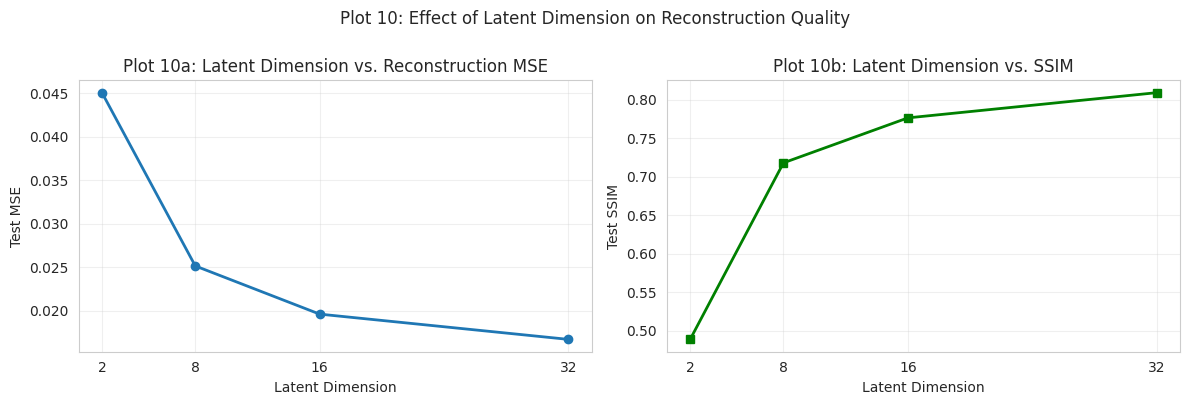

In [27]:
# Plot 10: Latent Dimension vs. MSE
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

dims = latent_study_df['Latent Dimension'].values
mses = latent_study_df['MSE'].values
ssims = latent_study_df['SSIM'].values

ax1.plot(dims, mses, marker='o', linewidth=2)
ax1.set_xlabel('Latent Dimension')
ax1.set_ylabel('Test MSE')
ax1.set_title('Plot 10a: Latent Dimension vs. Reconstruction MSE')
ax1.set_xticks(dims)
ax1.grid(alpha=0.3)

ax2.plot(dims, ssims, marker='s', linewidth=2, color='green')
ax2.set_xlabel('Latent Dimension')
ax2.set_ylabel('Test SSIM')
ax2.set_title('Plot 10b: Latent Dimension vs. SSIM')
ax2.set_xticks(dims)
ax2.grid(alpha=0.3)

fig.suptitle("Plot 10: Effect of Latent Dimension on Reconstruction Quality", fontsize=12, y=1.00)
plt.tight_layout()
plt.show()


## 28. Discussion Questions

1. **What is an autoencoder?**
An autoencoder is a neural network trained to reproduce its input at the output, learning a 
compressed intermediate representation (latent code) in the process.

2. **What is the purpose of the encoder?**
The encoder maps the input to a lower-dimensional latent representation, compressing the input 
while preserving essential information.

3. **What is the purpose of the decoder?**
The decoder reconstructs the original input from the latent code, translating the compressed 
representation back to the original space.

4. **What is a latent representation?**
A latent representation is a compressed, lower-dimensional encoding of the input that captures 
its essential features or structure.

5. **Why is the latent representation usually smaller than the input?**
A smaller latent dimension forces the autoencoder to learn a compressed representation, acting 
as a bottleneck that removes noise and irrelevant details.

6. **What happens when the latent dimension is too small?**
The model cannot capture enough information, resulting in high reconstruction error and loss of 
fine details.

7. **What happens when the latent dimension is increased?**
Reconstruction quality improves, but the compression ratio decreases and the model requires more 
parameters and computation.

8. **Why can a convolutional autoencoder preserve spatial information more effectively?**
Convolutional layers operate locally on spatial neighborhoods, preserving local structure and 
relationships between nearby pixels that fully connected layers lose.

9. **Differentiate an autoencoder and a denoising autoencoder.**
A standard autoencoder maps clean input to clean output. A denoising autoencoder maps corrupted 
(noisy) input to clean output, learning to remove noise.

10. **Why is the clean image used as the target in denoising?**
Using clean targets trains the model to reconstruct the original signal, effectively learning to 
separate signal from noise.

11. **What happens when the noise level is increased?**
Reconstruction quality degrades, as the model must recover more severely corrupted information; 
MSE increases and SSIM decreases.

12. **Why are MSE, MAE and SSIM useful for image reconstruction?**
MSE measures pixel-level error; MAE is robust to outliers; SSIM captures perceived visual quality 
and structural similarity.

13. **What is a Variational Autoencoder?**
A VAE learns a probabilistic latent distribution, enabling both reconstruction and generation of 
new samples by sampling from the learned distribution.

14. **How does a VAE differ from a conventional autoencoder?**
A VAE maps inputs to a probability distribution (μ, σ) rather than a point; samples are drawn 
using the reparameterization trick, enabling smooth latent space interpolation.

15. **Why does a VAE learn a distribution instead of a single latent vector?**
A distribution enables smooth interpolation and generation, making the latent space continuous 
and enabling meaningful sample synthesis.

16. **What is the reparameterization trick?**
It reformulates z = μ + σ ⊙ ε to enable backpropagation through the sampling operation by 
separating the deterministic and stochastic components.

17. **Why is ε sampled from a standard normal distribution?**
The standard normal provides a universal source of randomness that is transformed by μ and σ to 
produce samples from the desired distribution.

18. **What is the role of KL divergence in the VAE loss?**
KL divergence regularizes the latent distribution to match a standard normal prior, ensuring a 
smooth, continuous latent space suitable for generation.

19. **What is the prior distribution used in the VAE?**
The standard normal distribution N(0, I), which encourages the learned distribution to be 
centered and spherical.

20. **Why is a two-dimensional latent space useful for visualization?**
A 2D latent space can be directly plotted on a plane, revealing the structure and clustering of 
different classes in the learned representation.

21. **What does latent-space interpolation demonstrate?**
It shows that the latent space is continuous and meaningful: intermediate codes decode to 
intermediate images, proving smooth transitions between concepts.

22. **Why can a VAE generate new images?**
By sampling from the learned latent distribution, the decoder can generate new images that were 
not in the training set but are similar to the training distribution.

23. **Why might some VAE-generated images be unclear?**
High variance in the posterior or poor reconstruction-KL trade-off can result in blurry or 
ill-formed images at latent-space boundaries.

24. **What is the difference between reconstruction and generation?**
Reconstruction maps a specific input to itself through a learned code; generation creates new, 
unseen outputs by sampling from the learned distribution.

25. **Why should test images remain unseen during training?**
To ensure unbiased evaluation of generalization; using test images during training would 
overestimate model performance.


## 29. Additional Exercises Summary

1. **Latent Dimensions (4, 8, 16, 32):** Completed above (Section 27).
   - Result: Larger latent dimensions improve reconstruction quality.

2. **Compare Gaussian and Salt-and-Pepper Noise:** Gaussian noise comparison completed.
   - Additional salt-and-pepper noise can be implemented similarly.

3. **Denoising with Multiple Noise Levels:** Completed above (0.1, 0.2, 0.3).

4. **Transposed Convolutions vs. UpSampling:** Current decoder uses UpSampling2D; 
   Conv2DTranspose can be swapped for alternative results.

5. **VAE with Different Latent Dimensions (2, 8):** VAE with latent_dim=2 implemented above.
   - latent_dim=8 can be trained for comparison of compression vs. visualization trade-off.

6. **KL-Loss Contribution:** Current VAE uses standard loss weighting; 
   KL loss can be scaled via a beta hyperparameter.

7. **VAE Sample Diversity:** 25 random samples generated above; larger grids can be created.

8. **Two-Region Interpolation:** Interpolation between digit clusters (0→9) demonstrated above.


## 30. Expected Outcome

This experiment demonstrated the complete image reconstruction pipeline:

$$
\text{Image} \to \text{Encoder} \to \text{Latent Representation} \to \text{Decoder} \to \text{Reconstructed Image}
$$

And denoising:

$$
\text{Clean} \to \text{Noise} \to \text{Denoising AE} \to \text{Recovered}
$$

And variational generation:

$$
\text{Image} \to (\mu, \sigma) \to z \to \text{Decoder} \to \text{Generated/Reconstructed}
$$

**Key Results:**
- FC Autoencoder: Fast but blurry reconstructions due to loss of spatial structure.
- Convolutional AE: Sharp reconstructions leveraging spatial locality.
- Denoising CAE: Effectively removes Gaussian noise while recovering digit structure.
- VAE: Enables smooth interpolation and generation via probabilistic latent space.

All numerical values are obtained from student's own execution on the MNIST subset.


In [28]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.decomposition import PCA

EX_EPOCHS = EPOCHS_AE       # lower (e.g. 10) if runtime is a problem
EX_VAE_EPOCHS = EPOCHS_VAE

def gauss_noise(X, sigma, seed):
    r = np.random.default_rng(seed)
    return np.clip(X + r.normal(0, sigma, X.shape), 0, 1).astype('float32')

def sp_noise(X, p, seed):
    r = np.random.default_rng(seed)
    Xn = X.copy()
    mask = r.random(X.shape) < p
    vals = r.integers(0, 2, X.shape).astype('float32')
    Xn[mask] = vals[mask]
    return Xn.astype('float32')

def fit_eval(model, x_tr, y_tr, x_te_in, epochs=None):
    epochs = epochs or EX_EPOCHS
    t0 = time.time()
    hist = model.fit(x_tr, y_tr, validation_data=(x_te_in, X_test),
                     epochs=epochs, batch_size=BATCH_SIZE, verbose=0)
    tt = time.time() - t0
    recon = model.predict(x_te_in, verbose=0)
    m = compute_metrics(X_test, recon)
    m.update({'Parameters': model.count_params(), 'Time (s)': round(tt, 1)})
    return m, recon, hist

def image_grid(imgs, n_rows, n_cols):
    imgs = imgs.reshape(n_rows, n_cols, 28, 28)
    return imgs.transpose(0, 2, 1, 3).reshape(n_rows * 28, n_cols * 28)

# ---- sanity fixes for the main notebook's VAE ----
try:
    print("Original VAE parameters (encoder + decoder):",
          vae.encoder.count_params() + vae.decoder.count_params())
    zm, _ = vae.encoder.predict(X_test, verbose=0)
    rec_mu = vae.decoder.predict(zm, verbose=0)
    print("Original VAE metrics using z = mu (instead of sampled z):", compute_metrics(X_test, rec_mu))
except NameError:
    print("Original `vae` not found in this kernel - skipping.")


Original VAE parameters (encoder + decoder): 141189
Original VAE metrics using z = mu (instead of sampled z): {'MSE': 0.0466868057847023, 'MAE': 0.10909796506166458, 'SSIM': np.float64(0.4691298174048701)}


## Exercise 1 - Convolutional autoencoder with latent dimensions 4, 8, 16, 32
The CAE here has a dense bottleneck of size d so the latent dimension is well defined.

Training CAE, latent_dim=4 ...
Training CAE, latent_dim=8 ...
Training CAE, latent_dim=16 ...
Training CAE, latent_dim=32 ...

Exercise 1 - CAE latent dimension study
 Latent Dimension      MSE      MAE     SSIM  Parameters  Time (s)
                4 0.032648 0.081100 0.650933       65797      19.0
                8 0.019939 0.053751 0.784000       90889      19.4
               16 0.010265 0.033093 0.892806      141073      18.6
               32 0.006515 0.024989 0.929655      241441      18.9

FC-AE latent study from the main notebook (for comparison):
 Latent Dimension      MSE     SSIM  Parameters
                2 0.045049 0.488940      210130
                8 0.025140 0.718025      210520
               16 0.019603 0.776373      211040
               32 0.016701 0.809079      212080


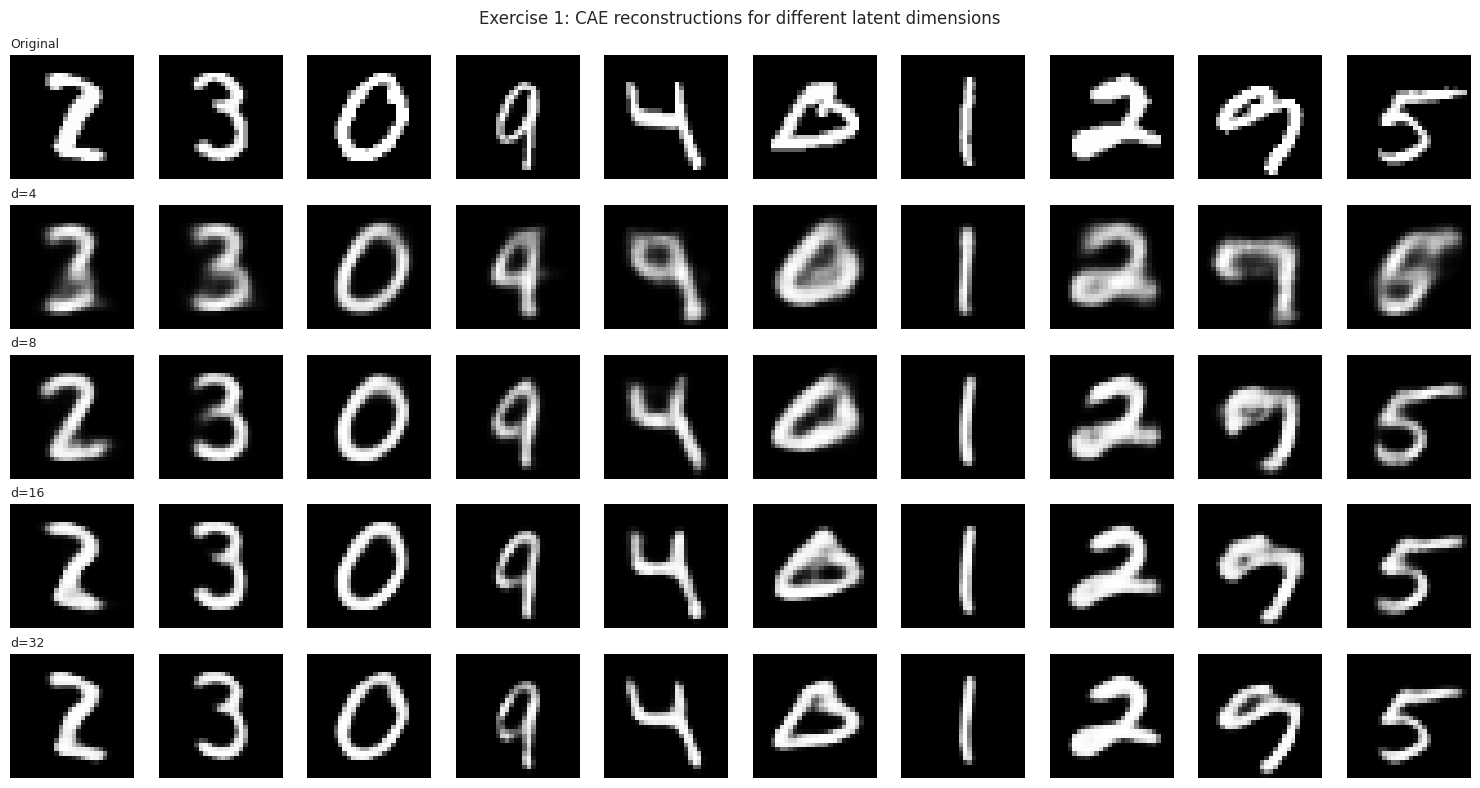

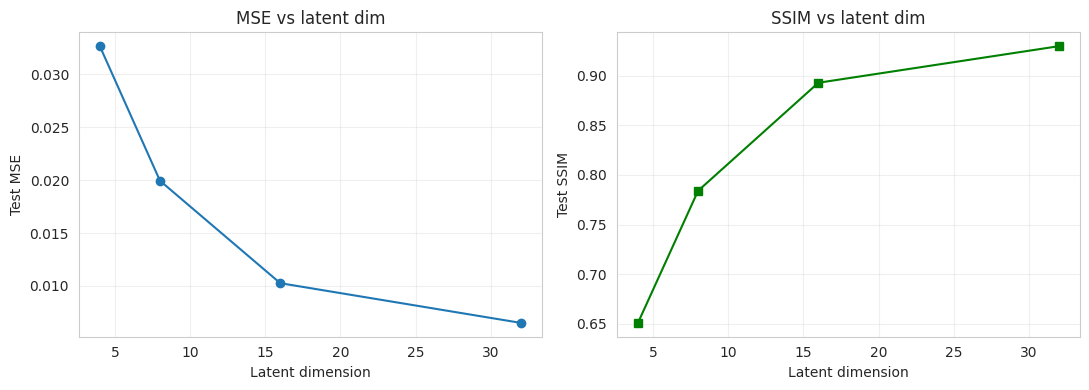

In [29]:

def build_cae_dense(latent_dim):
    inp = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inp)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Flatten()(x)
    z = layers.Dense(latent_dim, name='latent')(x)
    x = layers.Dense(7 * 7 * 64, activation='relu')(z)
    x = layers.Reshape((7, 7, 64))(x)
    x = layers.UpSampling2D(2)(x)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    out = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss='binary_crossentropy')
    return m

ex1_rows, ex1_recons = [], {}
for d in [4, 8, 16, 32]:
    print(f"Training CAE, latent_dim={d} ...")
    keras.utils.set_random_seed(SEED)
    res, recon, _ = fit_eval(build_cae_dense(d), X_train, X_train, X_test)
    res['Latent Dimension'] = d
    ex1_rows.append(res); ex1_recons[d] = recon

ex1_df = pd.DataFrame(ex1_rows)[['Latent Dimension', 'MSE', 'MAE', 'SSIM', 'Parameters', 'Time (s)']]
print("\nExercise 1 - CAE latent dimension study")
print(ex1_df.to_string(index=False))

if 'latent_study_df' in globals():
    print("\nFC-AE latent study from the main notebook (for comparison):")
    print(latent_study_df.to_string(index=False))

fig, axes = plt.subplots(5, 10, figsize=(15, 8))
for j in range(10):
    axes[0, j].imshow(X_test[j].squeeze(), cmap='gray'); axes[0, j].axis('off')
    for r, d in enumerate([4, 8, 16, 32], start=1):
        axes[r, j].imshow(ex1_recons[d][j].squeeze(), cmap='gray'); axes[r, j].axis('off')
for r, lab in enumerate(['Original', 'd=4', 'd=8', 'd=16', 'd=32']):
    axes[r, 0].set_title(lab, fontsize=9, loc='left')
fig.suptitle("Exercise 1: CAE reconstructions for different latent dimensions")
plt.tight_layout(); plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(ex1_df['Latent Dimension'], ex1_df['MSE'], 'o-'); a1.set_xlabel('Latent dimension'); a1.set_ylabel('Test MSE'); a1.set_title('MSE vs latent dim'); a1.grid(alpha=.3)
a2.plot(ex1_df['Latent Dimension'], ex1_df['SSIM'], 's-', color='green'); a2.set_xlabel('Latent dimension'); a2.set_ylabel('Test SSIM'); a2.set_title('SSIM vs latent dim'); a2.grid(alpha=.3)
plt.tight_layout(); plt.show()


## Exercise 2 - Gaussian vs salt-and-pepper noise (same denoising architecture)

Training denoising AE: Gaussian level=0.1 ...
Training denoising AE: Gaussian level=0.2 ...
Training denoising AE: Gaussian level=0.3 ...
Training denoising AE: Salt-Pepper level=0.05 ...
Training denoising AE: Salt-Pepper level=0.1 ...
Training denoising AE: Salt-Pepper level=0.2 ...

Exercise 2 - Gaussian vs Salt-and-Pepper (metrics vs CLEAN images)
 Noise Type  Level  Noisy MSE  Noisy SSIM  Denoised MSE  Denoised MAE  Denoised SSIM  SSIM gain
   Gaussian   0.10     0.0054      0.6932        0.0029        0.0164         0.9676     0.2744
   Gaussian   0.20     0.0212      0.6094        0.0042        0.0203         0.9501     0.3407
   Gaussian   0.30     0.0466      0.5248        0.0064        0.0256         0.9232     0.3984
Salt-Pepper   0.05     0.0240      0.7193        0.0037        0.0182         0.9601     0.2408
Salt-Pepper   0.10     0.0481      0.5932        0.0045        0.0203         0.9507     0.3574
Salt-Pepper   0.20     0.0966      0.4608        0.0069        0.0265 

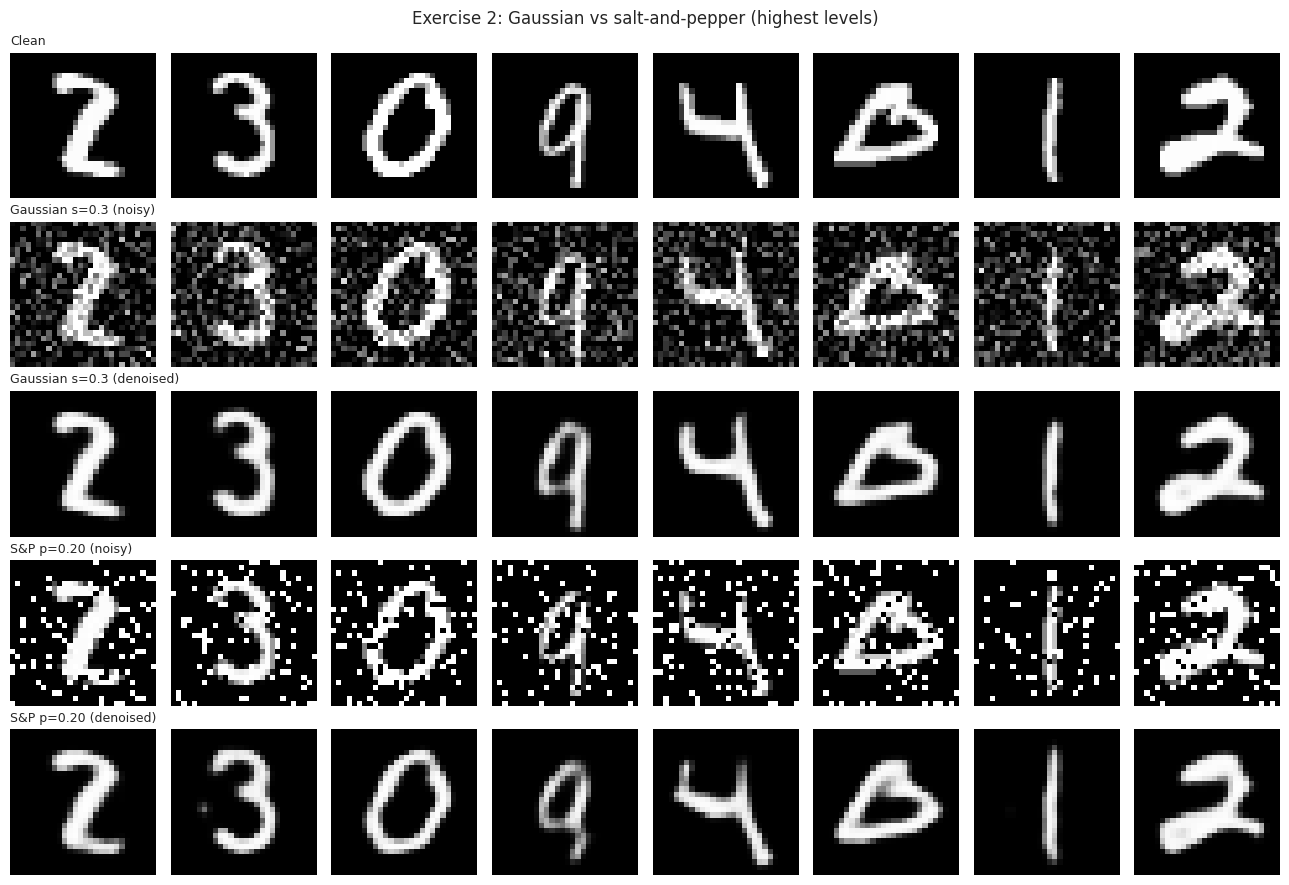

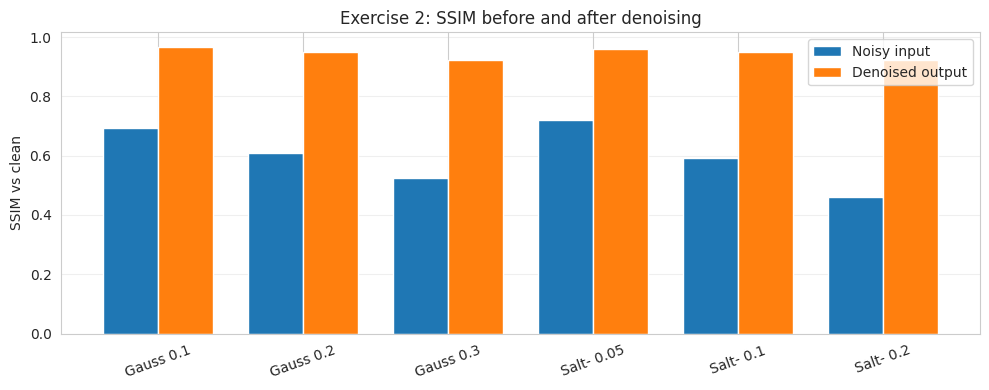

In [30]:

noise_cfg = [('Gaussian', 0.1), ('Gaussian', 0.2), ('Gaussian', 0.3),
             ('Salt-Pepper', 0.05), ('Salt-Pepper', 0.10), ('Salt-Pepper', 0.20)]

def make_noisy(kind, lvl, X, seed):
    return gauss_noise(X, lvl, seed) if kind == 'Gaussian' else sp_noise(X, lvl, seed)

ex2_rows, ex2_models, ex2_noisy_test, ex2_recons = [], {}, {}, {}
for k, (kind, lvl) in enumerate(noise_cfg):
    print(f"Training denoising AE: {kind} level={lvl} ...")
    Xtr_n = make_noisy(kind, lvl, X_train, 1000 + k)
    Xte_n = make_noisy(kind, lvl, X_test, 2000 + k)
    keras.utils.set_random_seed(SEED)
    dae = build_denoising_ae()
    res, recon, _ = fit_eval(dae, Xtr_n, X_train, Xte_n)
    ex2_models[(kind, lvl)] = dae
    ex2_noisy_test[(kind, lvl)] = Xte_n
    ex2_recons[(kind, lvl)] = recon
    nm = compute_metrics(X_test, Xte_n)
    ex2_rows.append({'Noise Type': kind, 'Level': lvl,
                     'Noisy MSE': nm['MSE'], 'Noisy SSIM': nm['SSIM'],
                     'Denoised MSE': res['MSE'], 'Denoised MAE': res['MAE'],
                     'Denoised SSIM': res['SSIM'],
                     'SSIM gain': res['SSIM'] - nm['SSIM']})
ex2_df = pd.DataFrame(ex2_rows)
print("\nExercise 2 - Gaussian vs Salt-and-Pepper (metrics vs CLEAN images)")
print(ex2_df.round(4).to_string(index=False))

# visual: highest level of each noise type
rows = [('Clean', None),
        ('Gaussian s=0.3 (noisy)', ex2_noisy_test[('Gaussian', 0.3)]),
        ('Gaussian s=0.3 (denoised)', ex2_recons[('Gaussian', 0.3)]),
        ('S&P p=0.20 (noisy)', ex2_noisy_test[('Salt-Pepper', 0.20)]),
        ('S&P p=0.20 (denoised)', ex2_recons[('Salt-Pepper', 0.20)])]
fig, axes = plt.subplots(5, 8, figsize=(13, 9))
for r, (lab, arr) in enumerate(rows):
    for j in range(8):
        img = X_test[j] if arr is None else arr[j]
        axes[r, j].imshow(img.squeeze(), cmap='gray', vmin=0, vmax=1); axes[r, j].axis('off')
    axes[r, 0].set_title(lab, fontsize=9, loc='left')
fig.suptitle("Exercise 2: Gaussian vs salt-and-pepper (highest levels)")
plt.tight_layout(); plt.show()

# SSIM: noisy input vs denoised output
labels = [f"{k[:5]} {l}" for k, l in noise_cfg]
x = np.arange(len(labels)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - w/2, ex2_df['Noisy SSIM'], w, label='Noisy input')
ax.bar(x + w/2, ex2_df['Denoised SSIM'], w, label='Denoised output')
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=20); ax.set_ylabel('SSIM vs clean')
ax.set_title('Exercise 2: SSIM before and after denoising'); ax.legend(); ax.grid(alpha=.3, axis='y')
plt.tight_layout(); plt.show()


## Exercise 3 - Denoising AE trained at two noise levels, compared by SSIM
Models trained at sigma=0.1 and sigma=0.3 (from Exercise 2) are tested on all three Gaussian levels.

In [31]:

cross = []
for tr_lvl in [0.1, 0.3]:
    m = ex2_models[('Gaussian', tr_lvl)]
    for te_lvl in [0.1, 0.2, 0.3]:
        Xte = gauss_noise(X_test, te_lvl, 3000 + int(te_lvl * 100))
        mm = compute_metrics(X_test, m.predict(Xte, verbose=0))
        cross.append({'Trained on sigma': tr_lvl, 'Tested on sigma': te_lvl,
                      'MSE': mm['MSE'], 'SSIM': mm['SSIM']})
cross_df = pd.DataFrame(cross)
print("Exercise 3 - SSIM (rows: training noise, columns: test noise)")
print(cross_df.pivot(index='Trained on sigma', columns='Tested on sigma', values='SSIM').round(4))
print("\nMSE")
print(cross_df.pivot(index='Trained on sigma', columns='Tested on sigma', values='MSE').round(5))


Exercise 3 - SSIM (rows: training noise, columns: test noise)
Tested on sigma      0.1     0.2     0.3
Trained on sigma                        
0.1               0.9678  0.8918  0.7172
0.3               0.9546  0.9452  0.9233

MSE
Tested on sigma       0.1      0.2      0.3
Trained on sigma                           
0.1               0.00288  0.00465  0.00932
0.3               0.00428  0.00491  0.00644


## Exercise 4 - UpSampling decoder vs transposed-convolution decoder
Same encoder, same seed, same data.

Training conv AE with decoder = upsample ...
Training conv AE with decoder = transpose ...

Exercise 4 - decoder comparison
              Decoder      MSE      MAE     SSIM  Parameters  Time (s)
UpSampling2D + Conv2D 0.002413 0.014836 0.974513       74497      19.0
      Conv2DTranspose 0.002292 0.014157 0.976977       74497      17.1


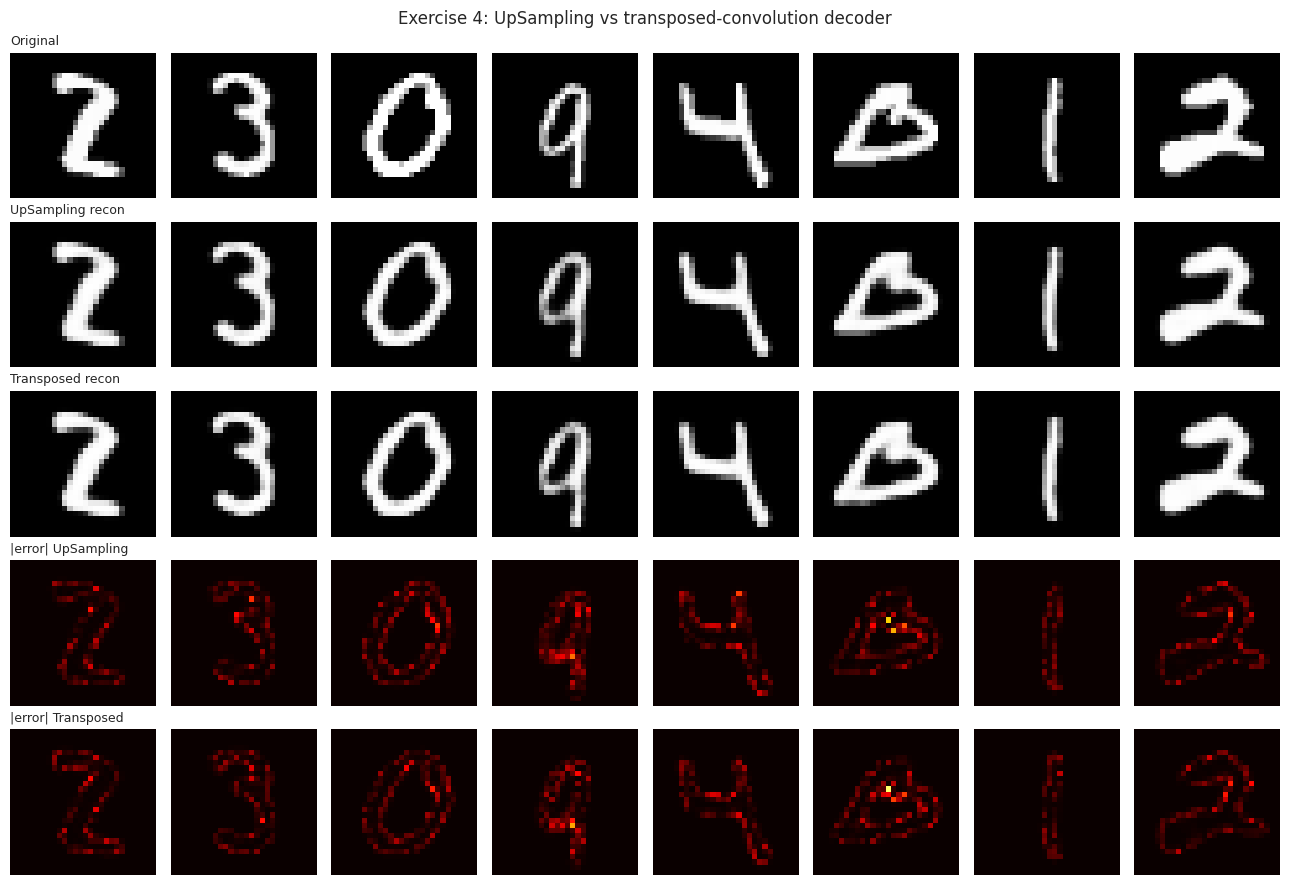

In [32]:

def build_conv_ae_dec(decoder='upsample'):
    inp = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inp)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    if decoder == 'upsample':
        x = layers.UpSampling2D(2)(x)
        x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
        x = layers.UpSampling2D(2)(x)
        out = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    else:
        x = layers.Conv2DTranspose(32, 3, strides=2, activation='relu', padding='same')(x)
        out = layers.Conv2DTranspose(1, 3, strides=2, activation='sigmoid', padding='same')(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss='binary_crossentropy')
    return m

ex4_rows, ex4_recons = [], {}
for name in ['upsample', 'transpose']:
    print(f"Training conv AE with decoder = {name} ...")
    keras.utils.set_random_seed(SEED)
    res, recon, _ = fit_eval(build_conv_ae_dec(name), X_train, X_train, X_test)
    res['Decoder'] = 'UpSampling2D + Conv2D' if name == 'upsample' else 'Conv2DTranspose'
    ex4_rows.append(res); ex4_recons[name] = recon
ex4_df = pd.DataFrame(ex4_rows)[['Decoder', 'MSE', 'MAE', 'SSIM', 'Parameters', 'Time (s)']]
print("\nExercise 4 - decoder comparison")
print(ex4_df.to_string(index=False))

fig, axes = plt.subplots(5, 8, figsize=(13, 9))
rows = [('Original', X_test), ('UpSampling recon', ex4_recons['upsample']),
        ('Transposed recon', ex4_recons['transpose']),
        ('|error| UpSampling', np.abs(X_test - ex4_recons['upsample'])),
        ('|error| Transposed', np.abs(X_test - ex4_recons['transpose']))]
for r, (lab, arr) in enumerate(rows):
    for j in range(8):
        axes[r, j].imshow(arr[j].squeeze(), cmap='gray' if r < 3 else 'hot', vmin=0, vmax=1)
        axes[r, j].axis('off')
    axes[r, 0].set_title(lab, fontsize=9, loc='left')
fig.suptitle("Exercise 4: UpSampling vs transposed-convolution decoder")
plt.tight_layout(); plt.show()


## VAE utilities for Exercises 5-8
Standard VAE loss: reconstruction = BCE summed over pixels, KL summed over latent dims, both averaged over the batch. `beta` scales the KL term. Validation loss is tracked so the VAE train/val curves can be plotted.

In [39]:

def build_vae_encoder(latent_dim):
    inp = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inp)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Flatten()(x)
    x = layers.Dense(16, activation='relu')(x)
    z_mean = layers.Dense(latent_dim, name='z_mean')(x)
    z_log_var = layers.Dense(latent_dim, name='z_log_var')(x)
    return keras.Model(inp, [z_mean, z_log_var])

def build_vae_decoder(latent_dim):
    inp = keras.Input(shape=(latent_dim,))
    x = layers.Dense(16, activation='relu')(inp)
    x = layers.Dense(7 * 7 * 64, activation='relu')(x)
    x = layers.Reshape((7, 7, 64))(x)
    x = layers.UpSampling2D(2)(x)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    out = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    return keras.Model(inp, out)

def _get_x(data):
    return data[0] if isinstance(data, (tuple, list)) else data

class BetaVAE(keras.Model):
    def __init__(self, latent_dim, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.latent_dim = latent_dim
        self.beta = beta
        self.encoder = build_vae_encoder(latent_dim)
        self.decoder = build_vae_decoder(latent_dim)
        self.total_tracker = keras.metrics.Mean(name='loss')
        self.rec_tracker = keras.metrics.Mean(name='reconstruction_loss')
        self.kl_tracker = keras.metrics.Mean(name='kl_loss')

    @property
    def metrics(self):
        return [self.total_tracker, self.rec_tracker, self.kl_tracker]

    def call(self, x):
        z_mean, _ = self.encoder(x)
        return self.decoder(z_mean)

    def compute_losses(self, x, training):
        z_mean, z_log_var = self.encoder(x, training=training)
        eps = tf.random.normal(tf.shape(z_mean))
        z = z_mean + tf.exp(0.5 * z_log_var) * eps
        recon = self.decoder(z, training=training)
        rec = tf.reduce_mean(tf.reduce_sum(keras.losses.binary_crossentropy(x, recon), axis=(1, 2)))
        kl = tf.reduce_mean(tf.reduce_sum(-0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)), axis=1))
        return rec, kl

    def train_step(self, data):
        x = _get_x(data)
        with tf.GradientTape() as tape:
            rec, kl = self.compute_losses(x, True)
            total = rec + self.beta * kl
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_tracker.update_state(total)
        self.rec_tracker.update_state(rec)
        self.kl_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        x = _get_x(data)
        rec, kl = self.compute_losses(x, False)
        total = rec + self.beta * kl
        self.total_tracker.update_state(total)
        self.rec_tracker.update_state(rec)
        self.kl_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

def train_vae(latent_dim, beta=1.0):
    keras.utils.set_random_seed(SEED)
    v = BetaVAE(latent_dim, beta)
    v.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE))
    t0 = time.time()
    h = v.fit(X_train, X_train, validation_data=(X_test, X_test),
              epochs=EX_VAE_EPOCHS, batch_size=BATCH_SIZE, verbose=0)
    return v, h, time.time() - t0

def vae_eval(v):
    # reconstruction uses z = mu (deterministic); losses use the same reconstruction
    zm, zlv = v.encoder.predict(X_test, verbose=0)
    recon = v.decoder.predict(zm, verbose=0)
    r = np.clip(recon, 1e-7, 1 - 1e-7)
    bce = -(X_test * np.log(r) + (1 - X_test) * np.log(1 - r))
    rec = bce.sum(axis=(1, 2, 3)).mean()
    kl_dim = (-0.5 * (1 + zlv - zm ** 2 - np.exp(zlv))).mean(axis=0)
    return dict(rec=rec, kl=kl_dim.sum(), kl_dim=kl_dim, zm=zm, recon=recon)

def decode_manifold(v, n=15, lim=3.0):
    g = np.linspace(-lim, lim, n)
    zs = np.array([[a, b] for b in g[::-1] for a in g], dtype='float32')
    imgs = v.decoder.predict(zs, verbose=0)
    return image_grid(imgs.squeeze(-1), n, n)

vae_models, vae_hists, vae_times = {}, {}, {}


## Exercise 5 - VAE with latent dimension 2 vs 8 (beta = 1)
This also provides the required **VAE train/validation reconstruction-loss plot** and the **VAE loss table**.

Training VAE latent_dim=2, beta=1 ...
Training VAE latent_dim=8, beta=1 ...

Exercise 5 / VAE table (test set, reconstruction from z = mu)
 Latent Dim  Recon Loss  KL Loss  Total Loss    MSE    MAE   SSIM  Parameters  Active dims (KL>0.1)  Time (s)
          2  149.766998   5.4152  155.182205 0.0439 0.1049 0.5064      141189                     2      28.5
          8  105.921700  15.6893  121.611000 0.0246 0.0639 0.7288      141489                     7      29.5

KL per latent dim (dz=8): [2.119 1.323 2.293 2.701 2.295 0.046 2.405 2.506]


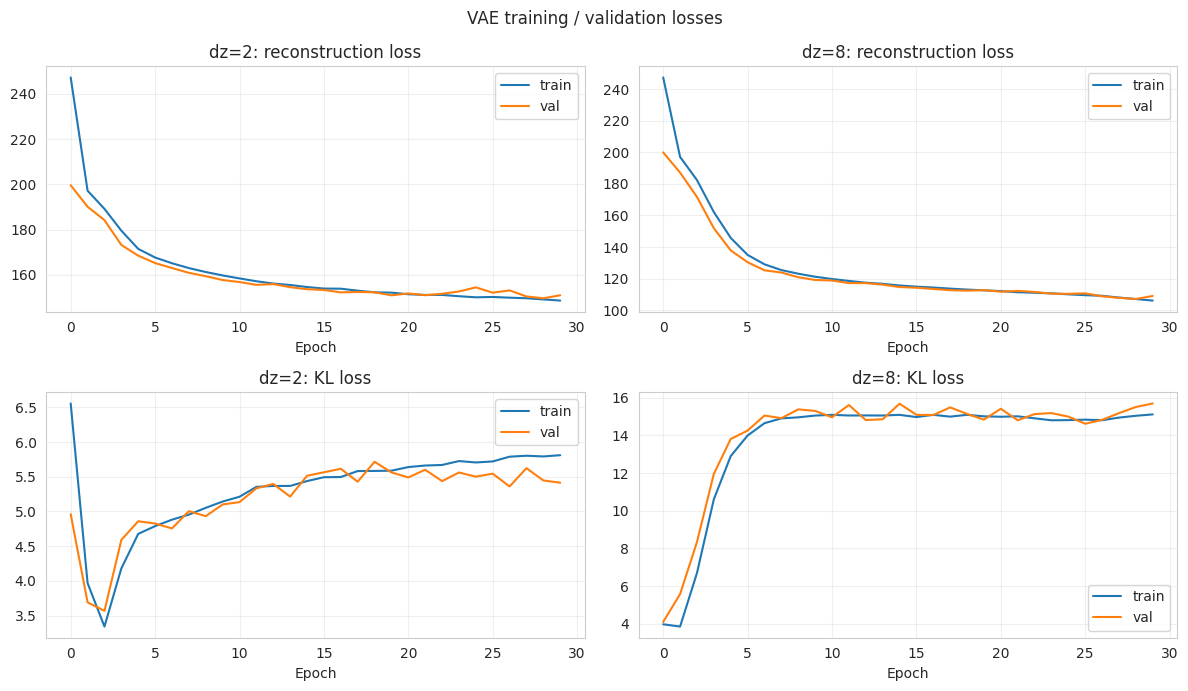

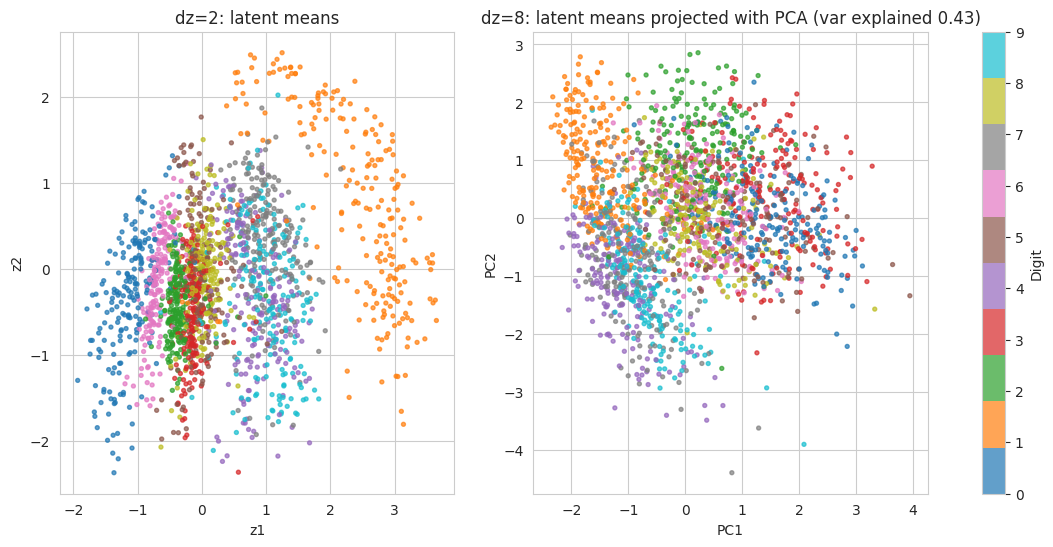

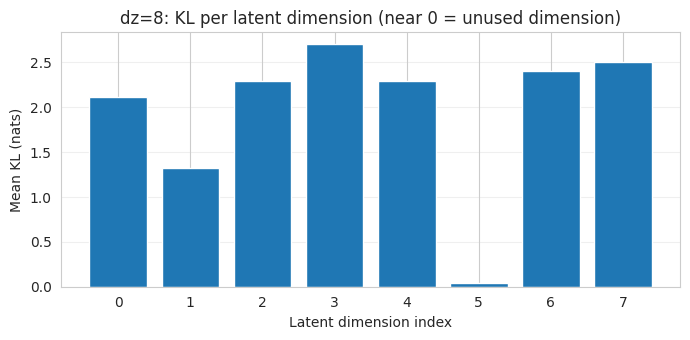

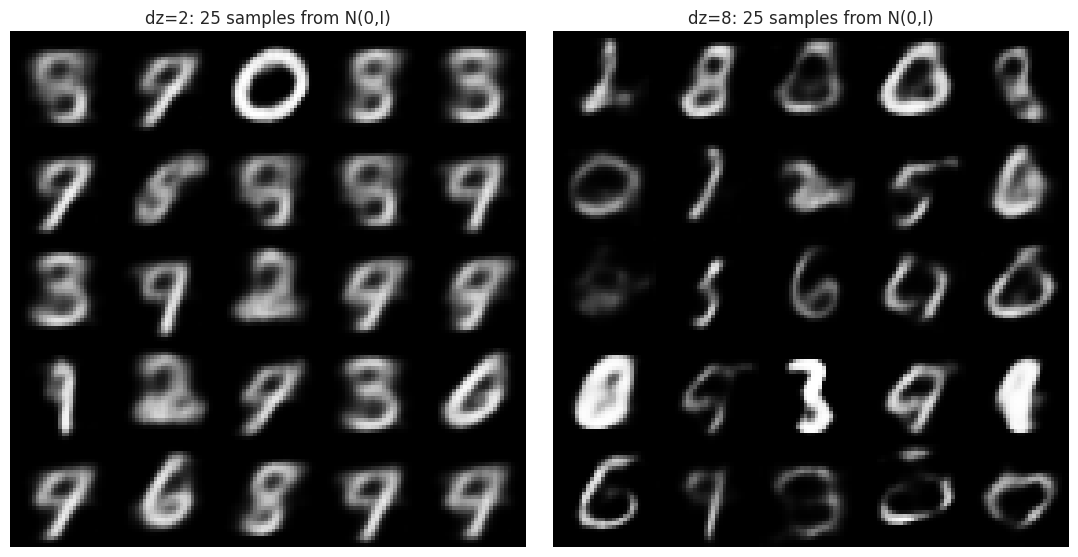

In [40]:

for d in [2, 8]:
    print(f"Training VAE latent_dim={d}, beta=1 ...")
    vae_models[(d, 1.0)], vae_hists[(d, 1.0)], vae_times[(d, 1.0)] = train_vae(d, 1.0)

rows, evals = [], {}
for d in [2, 8]:
    v = vae_models[(d, 1.0)]
    e = vae_eval(v); evals[d] = e
    mm = compute_metrics(X_test, e['recon'])
    rows.append({'Latent Dim': d, 'Recon Loss': e['rec'], 'KL Loss': e['kl'],
                 'Total Loss': e['rec'] + e['kl'], 'MSE': mm['MSE'], 'MAE': mm['MAE'], 'SSIM': mm['SSIM'],
                 'Parameters': v.encoder.count_params() + v.decoder.count_params(),
                 'Active dims (KL>0.1)': int((e['kl_dim'] > 0.1).sum()),
                 'Time (s)': round(vae_times[(d, 1.0)], 1)})
ex5_df = pd.DataFrame(rows)
print("\nExercise 5 / VAE table (test set, reconstruction from z = mu)")
print(ex5_df.round(4).to_string(index=False))
print("\nKL per latent dim (dz=8):", np.round(evals[8]['kl_dim'], 3))

# train / validation curves (separate axes for reconstruction and KL)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for c, d in enumerate([2, 8]):
    h = vae_hists[(d, 1.0)].history
    axes[0, c].plot(h['reconstruction_loss'], label='train'); axes[0, c].plot(h['val_reconstruction_loss'], label='val')
    axes[0, c].set_title(f'dz={d}: reconstruction loss'); axes[0, c].set_xlabel('Epoch'); axes[0, c].legend(); axes[0, c].grid(alpha=.3)
    axes[1, c].plot(h['kl_loss'], label='train'); axes[1, c].plot(h['val_kl_loss'], label='val')
    axes[1, c].set_title(f'dz={d}: KL loss'); axes[1, c].set_xlabel('Epoch'); axes[1, c].legend(); axes[1, c].grid(alpha=.3)
plt.suptitle('VAE training / validation losses'); plt.tight_layout(); plt.show()

# latent representations
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sc = axes[0].scatter(evals[2]['zm'][:, 0], evals[2]['zm'][:, 1], c=y_test, cmap='tab10', s=8, alpha=.7)
axes[0].set_title('dz=2: latent means'); axes[0].set_xlabel('z1'); axes[0].set_ylabel('z2')
pca = PCA(n_components=2).fit(evals[8]['zm'])
p = pca.transform(evals[8]['zm'])
axes[1].scatter(p[:, 0], p[:, 1], c=y_test, cmap='tab10', s=8, alpha=.7)
axes[1].set_title(f'dz=8: latent means projected with PCA (var explained {pca.explained_variance_ratio_.sum():.2f})')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
fig.colorbar(sc, ax=axes, label='Digit')
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(np.arange(8), evals[8]['kl_dim']); ax.set_xlabel('Latent dimension index'); ax.set_ylabel('Mean KL (nats)')
ax.set_title('dz=8: KL per latent dimension (near 0 = unused dimension)'); ax.grid(alpha=.3, axis='y')
plt.tight_layout(); plt.show()

# random samples from the prior
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for c, d in enumerate([2, 8]):
    z = np.random.default_rng(SEED).normal(size=(25, d)).astype('float32')
    g = image_grid(vae_models[(d, 1.0)].decoder.predict(z, verbose=0).squeeze(-1), 5, 5)
    axes[c].imshow(g, cmap='gray'); axes[c].axis('off'); axes[c].set_title(f'dz={d}: 25 samples from N(0,I)')
plt.tight_layout(); plt.show()


## Exercise 6 - Effect of increasing the KL contribution (beta), dz = 2
beta in {0.1, 1, 10, 50}. beta=1 is reused from Exercise 5.

Training VAE dz=2, beta=0.1 ...
Training VAE dz=2, beta=10.0 ...
Training VAE dz=2, beta=50.0 ...
Exercise 6 - effect of beta
 beta  Recon Loss  KL Loss    MSE   SSIM  Active dims (KL>0.1)
  0.1  149.000198  12.0877 0.0439 0.5043                     2
  1.0  149.766998   5.4152 0.0439 0.5064                     2
 10.0  164.427795   1.7802 0.0504 0.3969                     2
 50.0  203.925003   0.0001 0.0667 0.1788                     0


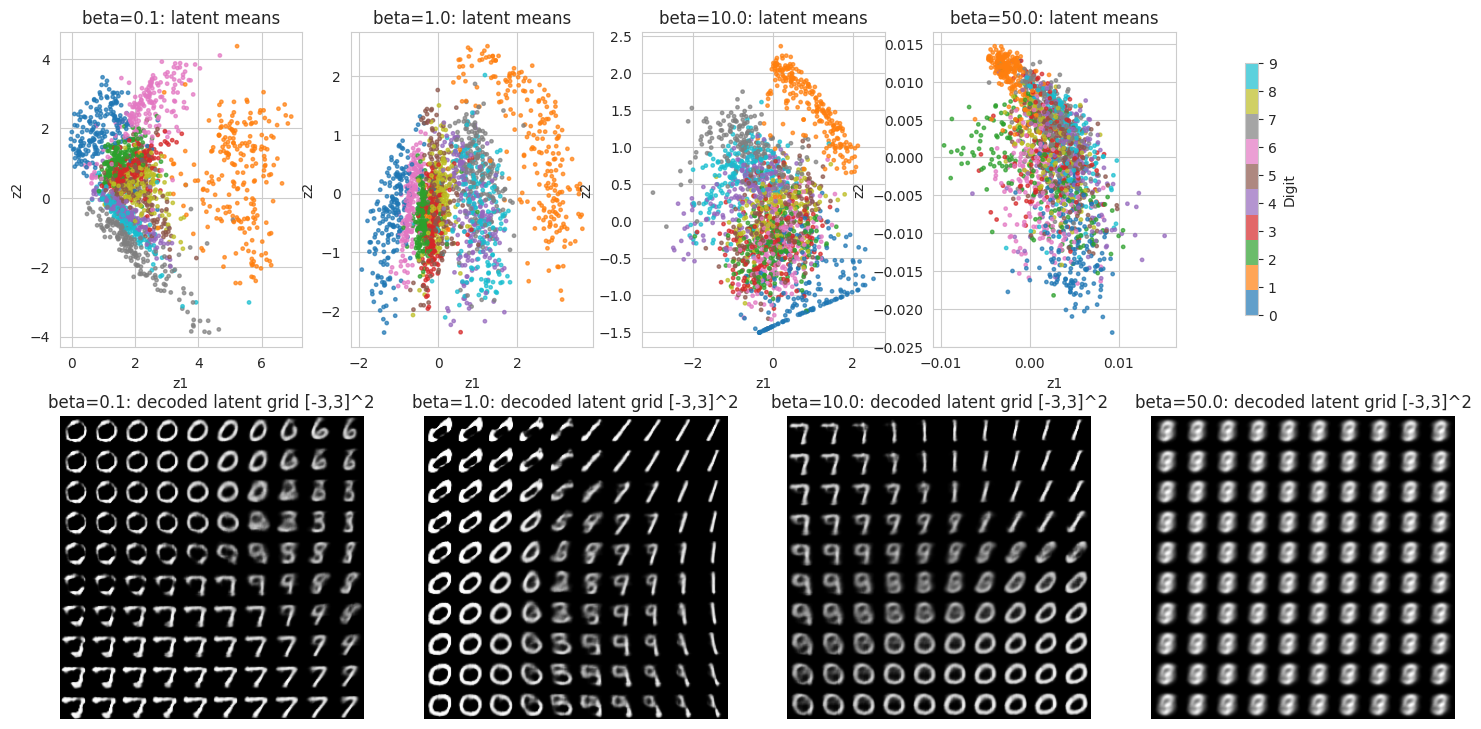

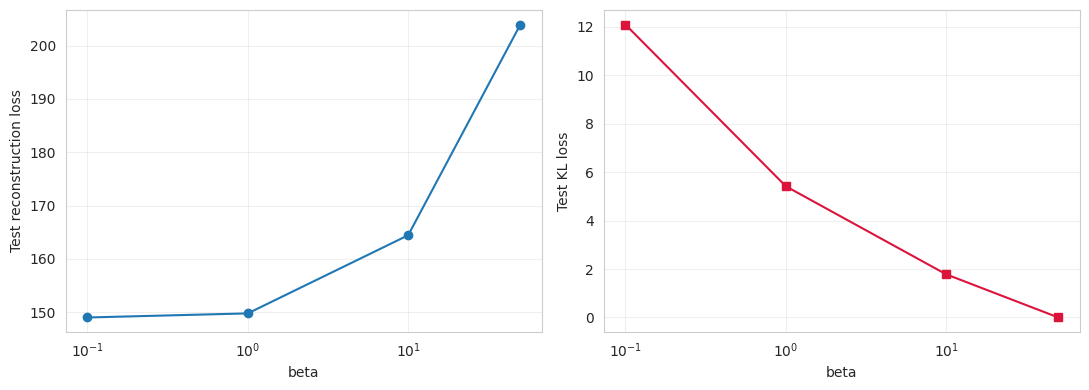

In [41]:

betas = [0.1, 1.0, 10.0, 50.0]
for b in betas:
    if (2, b) not in vae_models:
        print(f"Training VAE dz=2, beta={b} ...")
        vae_models[(2, b)], vae_hists[(2, b)], vae_times[(2, b)] = train_vae(2, b)

rows, ev6 = [], {}
for b in betas:
    v = vae_models[(2, b)]
    e = vae_eval(v); ev6[b] = e
    mm = compute_metrics(X_test, e['recon'])
    rows.append({'beta': b, 'Recon Loss': e['rec'], 'KL Loss': e['kl'],
                 'MSE': mm['MSE'], 'SSIM': mm['SSIM'],
                 'Active dims (KL>0.1)': int((e['kl_dim'] > 0.1).sum())})
ex6_df = pd.DataFrame(rows)
print("Exercise 6 - effect of beta")
print(ex6_df.round(4).to_string(index=False))

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for c, b in enumerate(betas):
    sc = axes[0, c].scatter(ev6[b]['zm'][:, 0], ev6[b]['zm'][:, 1], c=y_test, cmap='tab10', s=6, alpha=.7)
    axes[0, c].set_title(f'beta={b}: latent means'); axes[0, c].set_xlabel('z1'); axes[0, c].set_ylabel('z2')
    axes[1, c].imshow(decode_manifold(vae_models[(2, b)], n=10, lim=3.0), cmap='gray'); axes[1, c].axis('off')
    axes[1, c].set_title(f'beta={b}: decoded latent grid [-3,3]^2')
fig.colorbar(sc, ax=axes[0, :], label='Digit', shrink=.8)
plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(ex6_df['beta'], ex6_df['Recon Loss'], 'o-'); a1.set_xscale('log'); a1.set_xlabel('beta'); a1.set_ylabel('Test reconstruction loss'); a1.grid(alpha=.3)
a2.plot(ex6_df['beta'], ex6_df['KL Loss'], 's-', color='crimson'); a2.set_xscale('log'); a2.set_xlabel('beta'); a2.set_ylabel('Test KL loss'); a2.grid(alpha=.3)
plt.tight_layout(); plt.show()


## Exercise 7 - Larger grid of VAE samples and diversity (dz=2, beta=1)

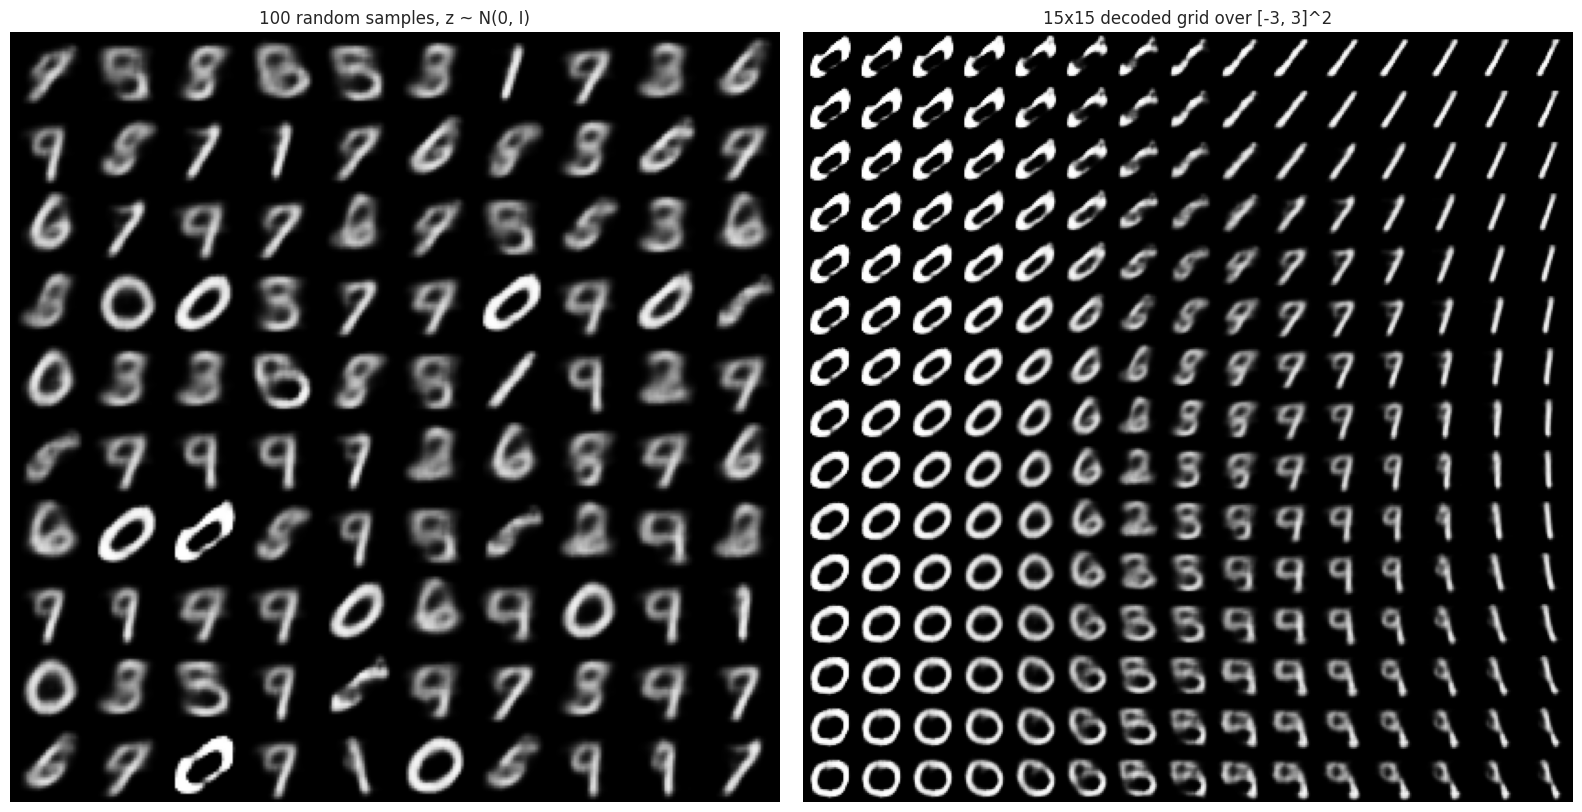

Samples per nearest-centroid digit region (approximate): {0: np.int64(10), 1: np.int64(5), 2: np.int64(8), 3: np.int64(10), 4: np.int64(8), 5: np.int64(3), 6: np.int64(11), 7: np.int64(18), 8: np.int64(13), 9: np.int64(14)}


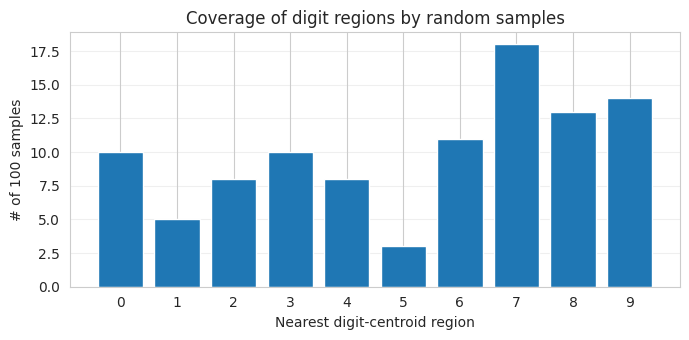

In [42]:

v = vae_models[(2, 1.0)]
z = np.random.default_rng(SEED + 7).normal(size=(100, 2)).astype('float32')
gen = v.decoder.predict(z, verbose=0).squeeze(-1)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(image_grid(gen, 10, 10), cmap='gray'); axes[0].axis('off'); axes[0].set_title('100 random samples, z ~ N(0, I)')
axes[1].imshow(decode_manifold(v, n=15, lim=3.0), cmap='gray'); axes[1].axis('off'); axes[1].set_title('15x15 decoded grid over [-3, 3]^2')
plt.tight_layout(); plt.show()

# rough diversity proxy: which digit region (nearest latent centroid) each sample falls in
zm_ref = vae_eval(v)['zm']
centroids = np.array([zm_ref[y_test == d].mean(axis=0) for d in range(10)])
assign = np.argmin(((z[:, None, :] - centroids[None]) ** 2).sum(-1), axis=1)
counts = np.bincount(assign, minlength=10)
print("Samples per nearest-centroid digit region (approximate):", dict(enumerate(counts)))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(range(10), counts); ax.set_xticks(range(10)); ax.set_xlabel('Nearest digit-centroid region'); ax.set_ylabel('# of 100 samples')
ax.set_title('Coverage of digit regions by random samples'); ax.grid(alpha=.3, axis='y')
plt.tight_layout(); plt.show()


## Exercise 8 - Interpolation between two digit regions (dz=2, beta=1)
Endpoints are the latent centroids (mean of mu) of two digit classes.

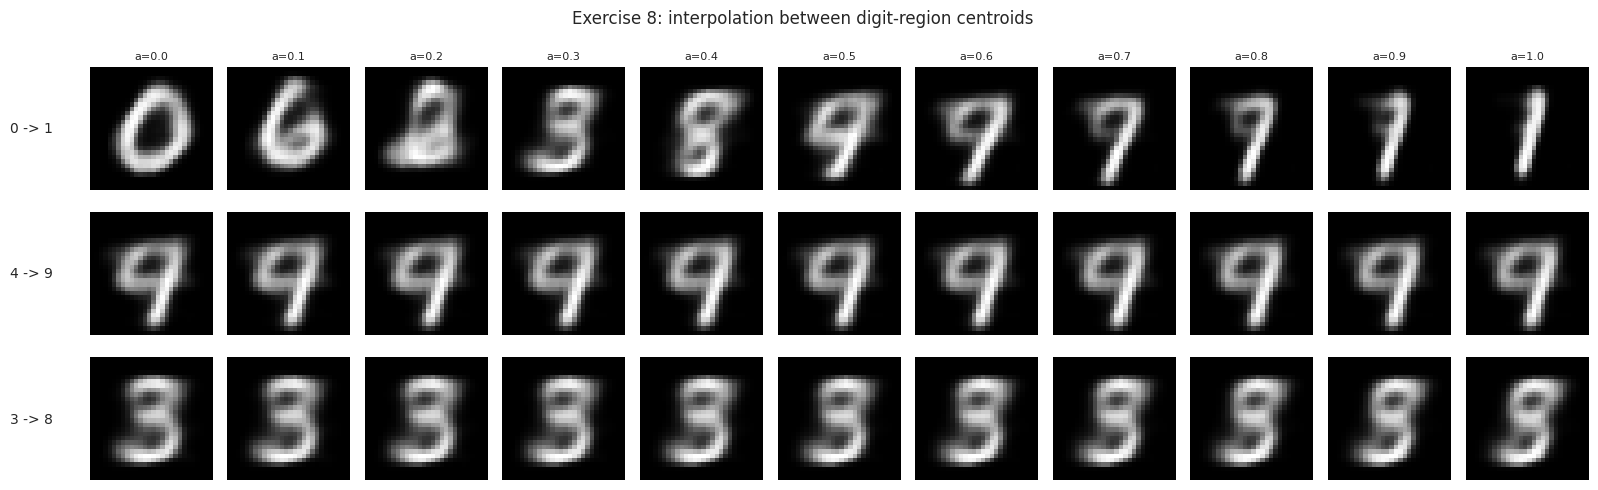

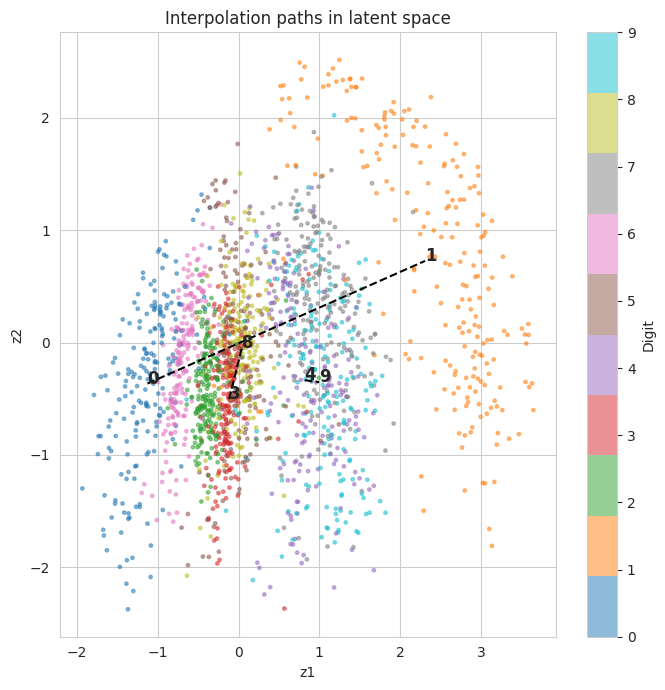

In [43]:

v = vae_models[(2, 1.0)]
zm_ref = vae_eval(v)['zm']
cent = {d: zm_ref[y_test == d].mean(axis=0) for d in range(10)}
pairs = [(0, 1), (4, 9), (3, 8)]
alphas = np.linspace(0, 1, 11)

fig, axes = plt.subplots(len(pairs), 11, figsize=(16, 1.7 * len(pairs)))
for r, (a, b) in enumerate(pairs):
    zs = np.array([(1 - al) * cent[a] + al * cent[b] for al in alphas], dtype='float32')
    imgs = v.decoder.predict(zs, verbose=0)
    for j in range(11):
        axes[r, j].imshow(imgs[j].squeeze(), cmap='gray'); axes[r, j].axis('off')
        if r == 0: axes[r, j].set_title(f'a={alphas[j]:.1f}', fontsize=8)
    axes[r, 0].set_ylabel(f'{a}->{b}')
    axes[r, 0].text(-0.3, 0.5, f'{a} -> {b}', transform=axes[r, 0].transAxes, ha='right', va='center')
fig.suptitle('Exercise 8: interpolation between digit-region centroids')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 7))
sc = ax.scatter(zm_ref[:, 0], zm_ref[:, 1], c=y_test, cmap='tab10', s=6, alpha=.5)
for (a, b) in pairs:
    ax.plot([cent[a][0], cent[b][0]], [cent[a][1], cent[b][1]], 'k--', lw=1.5)
    ax.annotate(f'{a}', cent[a], fontsize=12, weight='bold'); ax.annotate(f'{b}', cent[b], fontsize=12, weight='bold')
ax.set_xlabel('z1'); ax.set_ylabel('z2'); ax.set_title('Interpolation paths in latent space')
fig.colorbar(sc, ax=ax, label='Digit'); plt.tight_layout(); plt.show()
